# Clearview Properties — Residential Price Analysis

**Technical notebook.** It documents the whole analysis end to end for the Clearview Properties brief: data quality review, exploratory analysis, modeling, and the evidence behind each decision.

The client's questions:

| # | Question |
|---|---|
| Q1 | Given a property's characteristics, what is a reasonable **price range** to list it at? |
| Q2 | Which characteristics have the **largest impact on sale price**, split into owner-modifiable vs structural/location? |
| Q3 | Among the modifiable characteristics, which improvements are a **profitable investment**? |
| Q4 | Is there a clear **market segmentation**, i.e. groups of properties that behave differently? |

## Contents
0. Setup and reproducibility
1. Data quality audit and cleaning
2. Exploratory data analysis and feature engineering
3. Q1 — Price range model (point estimate + calibrated intervals)
4. Q2 — Price drivers (structural/location vs. owner-modifiable)
5. Q3 — Improvement return on investment (counterfactual uplift vs. cost benchmarks)
6. Q4 — Market segmentation (unsupervised clustering + segment behavior)
7. Conclusions, limitations and next steps

## Use of AI tools
As required by the brief: AI coding assistants — Claude (Anthropic, via Claude Code) for the initial Phase 0–1 setup and audit structure, and Google Antigravity (Gemini) for extending the audit, developing Phases 2–7, running validation experiments, and preparing the client presentation — were used as pair-programming tools. All methodological decisions, model checks, and interpretations were verified directly against executed notebook outputs.

## 0. Setup and reproducibility

All randomness in this notebook comes from one constant, `SEED`. It is passed as `random_state` to every split, cross-validation splitter, model, clustering algorithm and bootstrap. The environment is pinned with `uv.lock`; see the README for setup instructions.

In [1]:
import os
import random
import re
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm

# --- Reproducibility -------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)              # legacy global state, for libraries that still use it
RNG = np.random.default_rng(SEED) # preferred generator for our own sampling/bootstrap
# Inherited by any worker subprocesses (e.g. joblib). It cannot change hashing in the
# already-running kernel, and none of our results depend on that.
os.environ["PYTHONHASHSEED"] = str(SEED)

# --- Paths (resolved from the project root, so it runs from any working directory) ---
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = ROOT / "main" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Display and chart defaults ----------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
# Colorblind-safe categorical slots (validated reference palette; max 3 hues per chart),
# plus a neutral gray for context marks and recessive text/grid tones.
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#9a9993",
          "text": "#0b0b0b", "text2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text2"], "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["text2"], "ytick.color": COLORS["text2"],
    "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
USD = mticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save_fig(fig, name):
    """Export a figure to main/figures/ (used later for the client deck)."""
    fig.savefig(FIG_DIR / f"{name}.png")


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print(f"Project root: {ROOT}")

Python 3.14.2 | pandas 3.0.0 | numpy 2.5.2 | scikit-learn 1.9.0 | matplotlib 3.11.1
Project root: G:\My Drive\Universidad\maestria_nueva\Semestre 2\Machine learning\Trabajo_final\final-proyect-ml


### Raw data, loaded as delivered

The raw file is never modified. Every cleaning step in Section 1 is applied in code to a copy.

`keep_default_na=False` makes pandas read the text exactly as written: only empty cells count as missing. Without it, pandas would silently turn codes such as `"NA"` or `"N/A"` into missing values, hiding part of the quality problem we need to measure.

In [2]:
raw = pd.read_csv(DATA_DIR / "Data.csv", keep_default_na=False, na_values=[""])
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 2,963 rows x 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,2693,903454020.0,30.0,RM,50.0,9000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,5.0,4.0,1919.0,1950.0,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0.0,Unf,0.0,610.0,610.0,GasA,Ex,N,FuseA,819.0,0.0,0.0,819.0,0.0,0.0,1.0,0.0,2.0,1.0,Gd,4.0,Typ,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,N,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,9.0,2006.0,WD,Abnorml,72000
1,252,906385010.0,20.0,RL,94.0,10402,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,CollgCr,Norm,Norm,1Fam,1Story,7.0,5.0,2009.0,2009.0,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1226.0,1226.0,GasA,Ex,Y,SBrkr,1226.0,0.0,0.0,1226.0,0.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,0.0,NaN,Attchd,2009.0,RFn,3.0,740.0,TA,TA,Y,0.0,36.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,198900
2,2146,907252020.0,60.0,RL,NaN,9375,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,8.0,5.0,2002.0,2002.0,Gable,CompShg,VinylSd,VinylSd,BrkFace,149.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1284.0,1284.0,GasA,Ex,Y,SBrkr,1284.0,885.0,0.0,2169.0,0.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,1.0,Gd,Attchd,2002.0,RFn,2.0,647.0,TA,TA,Y,192.0,87.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,8.0,2007.0,WD,Normal,228500
3,2480,531451290.0,60.0,RL,70.0,9370,Pave,NaN,IR2,Lvl,AllPub,Inside,Gtl,SawyerW,Norm,Norm,1Fam,2Story,6.0,5.0,1992.0,1993.0,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,758.0,Unf,0.0,78.0,836.0,GasA,Ex,Y,SBrkr,844.0,887.0,0.0,1731.0,1.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,0.0,NaN,Attchd,1992.0,RFn,2.0,462.0,TA,TA,Y,307.0,85.0,0.0,0.0,224.0,0.0,NaN,NaN,Othr,3000.0,10.0,2006.0,WD,Family,248500
4,316,916386010.0,20.0,RL,88.0,11896,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,1Story,7.0,5.0,2008.0,2008.0,Gable,CompShg,VinylSd,VinylSd,Stone,60.0,Gd,TA,PConc,Gd,TA,No,GLQ,78.0,Unf,0.0,1258.0,1336.0,GasA,Ex,Y,SBrkr,1346.0,0.0,0.0,NaN,1.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,1.0,TA,Attchd,2008.0,Fin,3.0,660.0,TA,TA,Y,100.0,48.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,220000


## 1. Data quality audit and cleaning

The brief warns that the data comes "as the client handed it over". The approach:

1. **Audit:** run a fixed set of checks against the data dictionary and basic logic, and count the rows affected.
2. **Repair** in a fixed order. Each step records what it changed in a **data quality log**.
3. **Re-audit:** run the same checks on the cleaned data to verify that the problems are gone.
4. Define the **analysis sample**: which sales the price models learn from.

Agreed principles:
- **Never invent a sale price.** Rows with an invalid target are removed, not repaired.
- **Repair a corrupted value only when the same row holds direct evidence** for the correct value. Otherwise mark it as missing.
- **Leave real gaps for the imputer**, which is fitted inside the model pipeline on training data only, so no information leaks from the test set.

### 1.1 Valid codes, read from the data dictionary

The dictionary states that every listed code appears in the file exactly as written. We parse it, so the valid codes come from the client's own documentation rather than from hard-coded lists.

In [3]:
def parse_dictionary(path, columns):
    """Return {column: set of valid codes} for every coded column in the data dictionary."""
    codes, current = {}, None
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.startswith("NOTES ON MISSING"):          # end of the variable section
            break
        header = re.match(r"^(\S.*?)\s{2,}\S", line)       # "Column Name   description"
        if header and header.group(1) in columns:
            current = header.group(1)
            continue
        entry = re.match(r"^\s{10,}(\S.*?)\s{2,}\S", line) # "      CODE   meaning"
        if current and entry:
            codes.setdefault(current, set()).add(entry.group(1))
        elif current == "Neighborhood" and "," in line:   # neighborhoods are listed inline
            codes[current] = {c.strip() for c in line.split(",")}
    return codes


VALID_CODES = parse_dictionary(DATA_DIR / "Data_Dictionary.txt", raw.columns)
CODED_TEXT_COLS = [c for c in VALID_CODES if c != "MS SubClass"]   # MS SubClass is a numeric code
print(f"{len(VALID_CODES)} coded columns parsed, e.g.:")
for col in ["MS Zoning", "Central Air", "Sale Type"]:
    print(f"  {col}: {sorted(VALID_CODES[col])}")
print(f"  Neighborhood: {len(VALID_CODES['Neighborhood'])} codes")

44 coded columns parsed, e.g.:
  MS Zoning: ['A (agr)', 'C (all)', 'FV', 'I (all)', 'RH', 'RL', 'RM']
  Central Air: ['N', 'Y']
  Sale Type: ['COD', 'CWD', 'Con', 'ConLD', 'ConLI', 'ConLw', 'New', 'Oth', 'VWD', 'WD']
  Neighborhood: 28 codes


### 1.2 Audit of the raw file

One function holds every check. It runs on the raw data now and on the cleaned data at the end of this section, so the same code shows both the problem and its fix.

In [4]:
ABSENT = "Absent"   # label used later for "this feature does not exist" (no pool, no garage...)


def as_code(s):
    """Text view of a coded column (numeric codes such as MS SubClass become '30', '120')."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("Int64").astype("string")
    return s.astype("string")


def audit(df):
    """Count the rows affected by each known class of data problem."""
    price = pd.to_numeric(df["SalePrice"], errors="coerce")
    lot_txt = df["Lot Area"].astype("string")
    if pd.api.types.is_numeric_dtype(df["Lot Area"]):
        lot, lot_units, lot_decimal = df["Lot Area"], pd.Series(False, index=df.index), (df["Lot Area"] % 1).fillna(0) != 0
    else:
        lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
        lot_units, lot_decimal = lot_txt.str.contains(r"[A-Za-z]", na=False), lot_txt.str.contains(r"\.", na=False)
    ppsf = price / df["Gr Liv Area"]

    label_space = pd.Series(False, index=df.index)   # fixed by removing surrounding spaces
    label_other = pd.Series(False, index=df.index)   # wrong case, synonym or placeholder
    for col, valid in VALID_CODES.items():
        s, ok = as_code(df[col]), list(valid | {ABSENT})
        bad = s.notna() & ~s.isin(ok)
        spaces = bad & s.str.strip().isin(ok)
        label_space |= spaces.fillna(False)
        label_other |= (bad & ~spaces).fillna(False)

    years = df[["Year Built", "Year Remod/Add", "Garage Yr Blt"]]
    components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
    checks = {
        "Empty rows (>90% of fields missing)": df.isna().mean(axis=1) > 0.9,
        "Exact duplicate rows (ignoring Order)": df.drop(columns="Order").duplicated(),
        "Extra rows for an already-seen PID": df["PID"].notna() & df["PID"].duplicated(),
        "Duplicated Order id": df["Order"].duplicated(),
        "SalePrice stored as text ($, commas)": df["SalePrice"].notna() & price.isna(),
        "SalePrice missing": df["SalePrice"].isna(),
        "SalePrice zero or negative": price <= 0,
        "SalePrice implausible (>10x median $/sqft)": ppsf > 10 * ppsf.median(),
        "Lot Area stored with units text": lot_units,
        "Lot Area with decimals (square meters)": lot_decimal,
        "Lot Area equal to zero": lot == 0,
        "Year later than 2010 (after study period)": (years > 2010).any(axis=1),
        "Remodel year earlier than build year": df["Year Remod/Add"] < df["Year Built"],
        "Sale year outside 2006-2010": ~df["Yr Sold"].between(2006, 2010) & df["Yr Sold"].notna(),
        "Category label with extra spaces": label_space,
        "Category label not in dictionary (case/synonym/placeholder)": label_other,
        "Gr Liv Area missing": df["Gr Liv Area"].isna(),
        "Gr Liv Area != 1st + 2nd + low-quality floor area": (components - df["Gr Liv Area"]).abs() > 1,
        "Garage Cars > 5 (sentinel 99)": df["Garage Cars"] > 5,
        "Garage Cars > 5 (sentinel 99)": df["Garage Cars"] > 5,
        "Garage Cars > 5 (sentinel 99)": df["Garage Cars"] > 5,
        "Garage Cars > 5 (sentinel 99)": df["Garage Cars"] > 5,
        "Garage Cars > 5 (sentinel 99)": df["Garage Cars"] > 5,
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="rows")


audit_raw = audit(raw)
audit_raw.to_frame("rows affected (raw)")

,rows affected (raw)
Empty rows (>90% of fields missing),3
Exact duplicate rows (ignoring Order),18
Extra rows for an already-seen PID,30
Duplicated Order id,20
"SalePrice stored as text ($, commas)",30
SalePrice missing,23
SalePrice zero or negative,5
SalePrice implausible (>10x median $/sqft),2
Lot Area stored with units text,20
Lot Area with decimals (square meters),30


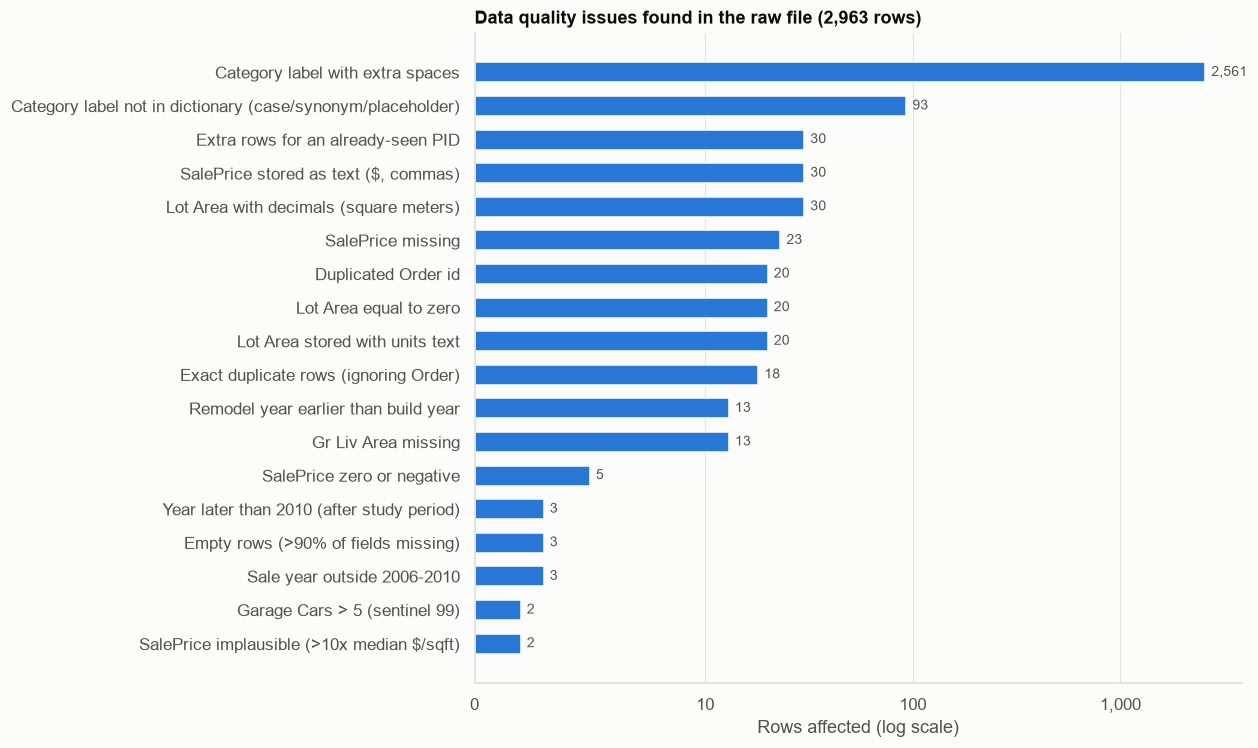

In [5]:
issues = audit_raw[audit_raw > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.36 * len(issues) + 1.2))
ax.barh(issues.index, issues.values, color=COLORS["blue"], height=0.6)
for y, v in enumerate(issues.values):
    ax.annotate(f"{v:,}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=COLORS["text2"])
ax.set_xscale("symlog", linthresh=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Rows affected (log scale)")
ax.set_title(f"Data quality issues found in the raw file ({len(raw):,} rows)")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_raw_data_quality_issues")
plt.show()

The structural missing values (no pool, no garage, and so on) are **not** counted as issues. The dictionary defines them as "the feature does not exist", and step 9 encodes them explicitly.

### 1.3 Repair pipeline

Each step works on a copy of the raw data and appends one or more entries to `QUALITY_LOG`: the issue, the rows affected, the action taken and the rationale.

In [6]:
QUALITY_LOG = []


def log(step, issue, rows, action, rationale):
    QUALITY_LOG.append({"step": step, "issue": issue, "rows_affected": int(rows),
                        "action": action, "rationale": rationale})


df = raw.copy()

**Step 1: Empty rows.** Three rows have no PID, no price and almost every field blank. They carry no information.

In [7]:
empty = df.isna().mean(axis=1) > 0.9
log(1, "Empty rows", empty.sum(), "Dropped", "No PID, no price, >90% of fields blank")
df = df.loc[~empty].copy()
print(f"Dropped {empty.sum()} empty rows -> {len(df):,} rows")

Dropped 3 empty rows -> 2,960 rows


**Step 2: Numbers stored as text, and wrong units.**
- `SalePrice` sometimes appears as `"$215,000"`. We strip the symbols; the value itself is correct.
- `Lot Area` sometimes appears as `"5362 sqft"`. We strip the units text.
- Some `Lot Area` values are written with a decimal point (e.g. `713.2`) while every other lot area is a whole number. These values are 10× smaller than typical lots, and one of them has a duplicate record with **7,677 sqft = 713.2 m² × 10.764**. They were recorded in **square meters**, so we convert them.
- `Lot Area = 0` is physically impossible. We set it to missing for the imputer.

In [8]:
SQM_TO_SQFT = 10.7639

# SalePrice: remove "$" and thousands separators
price_txt = df["SalePrice"].astype("string")
has_symbols = price_txt.str.contains(r"[$,]", na=False)
df["SalePrice"] = pd.to_numeric(price_txt.str.replace(r"[$,\s]", "", regex=True), errors="coerce")
log(2, "SalePrice stored as text", has_symbols.sum(), "Removed '$' and ',' and converted to number",
    "Formatting problem only; the amount is valid")

# Lot Area: units text, square meters, zeros
lot_txt = df["Lot Area"].astype("string").str.strip()
has_units = lot_txt.str.contains(r"[A-Za-z]", na=False)
in_sqm = lot_txt.str.contains(r"\.", na=False)
lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
lot_before_conversion = lot.copy()
lot = lot.where(~in_sqm, (lot * SQM_TO_SQFT).round())
zero_lot = lot == 0
df["Lot Area"] = lot.mask(zero_lot)
log(2, "Lot Area with units text ('sqft')", has_units.sum(), "Removed text, kept the number",
    "Formatting problem only")
log(2, "Lot Area recorded in square meters", in_sqm.sum(), "Multiplied by 10.764 and rounded",
    "Only decimal values in a whole-number column, ~10x below typical lots, confirmed by a duplicate record")
log(2, "Lot Area equal to zero", zero_lot.sum(), "Set to missing (imputed later in the pipeline)",
    "A lot cannot have zero area")

# Identifier-like numeric codes read as floats -> integers
df["PID"] = df["PID"].astype("Int64")
df["MS SubClass"] = df["MS SubClass"].astype("Int64")

In [9]:
# Evidence for the square-meter conversion: corrupted values vs. their neighborhood's typical lot
nbhd_median_lot = lot.where(~in_sqm).groupby(df["Neighborhood"]).median()
sqm_evidence = pd.DataFrame({
    "PID": df.loc[in_sqm, "PID"],
    "Neighborhood": df.loc[in_sqm, "Neighborhood"],
    "value as recorded": lot_before_conversion[in_sqm],
    "converted to sqft": lot[in_sqm],
    "neighborhood median (sqft)": df.loc[in_sqm, "Neighborhood"].map(nbhd_median_lot),
})
sqm_evidence["recorded / median"] = (sqm_evidence["value as recorded"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
sqm_evidence["converted / median"] = (sqm_evidence["converted to sqft"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
print("Median ratio to the neighborhood's typical lot -> as recorded: "
      f"{sqm_evidence['recorded / median'].median():.2f} | after conversion: {sqm_evidence['converted / median'].median():.2f}")
sqm_evidence.head(10)

Median ratio to the neighborhood's typical lot -> as recorded: 0.10 | after conversion: 1.02


,PID,Neighborhood,value as recorded,converted to sqft,neighborhood median (sqft),recorded / median,converted / median
27,533350120,Veenker,1512.4,16279.0,13165.0,0.11,1.24
45,907192030,CollgCr,830.1,8935.0,9675.0,0.09,0.92
82,905107240,Sawyer,960.1,10334.0,9402.0,0.1,1.1
246,905300020,Sawyer,947.6,10200.0,9402.0,0.1,1.08
427,527402380,NAmes,868.9,9353.0,9486.0,0.09,0.99
460,528427020,Somerst,893.0,9612.0,8125.0,0.11,1.18
483,923277030,Mitchel,613.1,6599.0,10172.0,0.06,0.65
639,902406020,OldTown,905.8,9750.0,7830.0,0.12,1.25
664,535305160,NAmes,713.2,7677.0,9486.0,0.08,0.81
747,534251320,NWAmes,909.5,9790.0,10944.0,0.08,0.89


**Step 3: Category labels.** Labels are matched to the dictionary codes after removing surrounding spaces and ignoring case (`rl`, `Rl`, ` RL` → `RL`). Two synonyms not in the dictionary are mapped explicitly: `paved` → `Pave` and `yes` → `Y`. Placeholders that mean "unknown" (`NA`, `N/A`, `??`, `unknown`) become missing; step 8 recovers them. The cell **asserts** that nothing else is left unmatched, so no label is dropped silently.

In [10]:
SYNONYMS = {"Street": {"paved": "Pave"}, "Central Air": {"yes": "Y"}}
PLACEHOLDERS = {"na", "n/a", "??", "unknown"}

changes = []
for col in CODED_TEXT_COLS:
    original = df[col].astype("string")
    lookup = {code.lower(): code for code in VALID_CODES[col]} | SYNONYMS.get(col, {})
    key = original.str.strip().str.lower()
    mapped = key.map(lookup)
    unmatched = original.notna() & mapped.isna()
    assert key[unmatched].isin(PLACEHOLDERS).all(), f"{col}: unexpected labels {set(original[unmatched])}"
    changed = original.notna() & (original != mapped).fillna(True)
    if changed.any():
        changes.append(pd.DataFrame({"column": col, "original": original[changed],
                                     "cleaned": mapped[changed].fillna("<missing>")}))
    df[col] = mapped.astype(object).where(mapped.notna(), np.nan)

label_changes = pd.concat(changes)
summary = (label_changes.assign(original=label_changes["original"].map(repr))
           .groupby(["column", "original", "cleaned"]).size().rename("rows").reset_index())
log(3, "Category labels with extra spaces / wrong case / synonyms", label_changes.index.nunique(),
    "Mapped to the dictionary code", "Same category written differently; would otherwise split one category into several")
summary

,column,original,cleaned,rows
0,Central Air,'YES',Y,8
1,Central Air,'Yes',Y,8
2,Central Air,'y',Y,7
3,Central Air,'yes',Y,8
4,MS Zoning,' RL',RL,10
5,MS Zoning,'RL ',RL,10
6,MS Zoning,'Rl',RL,10
7,MS Zoning,'rl',RL,10
8,Neighborhood,'??',<missing>,4
9,Neighborhood,'N/A',<missing>,4


**Step 4: Duplicates.** Once formats are normalized (step 2), more rows become exact copies: `"$330,000"` and `330000` now match. Exact copies are dropped first. Then we look at PIDs that still appear more than once. A PID identifies a property, and a property could legitimately sell twice, so we check whether the repeated rows describe the **same sale** (same month and year).

In [11]:
exact_dup = df.drop(columns="Order").duplicated()
log(4, "Exact duplicate rows", exact_dup.sum(), "Dropped (kept first)", "Same sale recorded twice")
df = df.loc[~exact_dup].copy()

repeated = df[df["PID"].duplicated(keep=False)].sort_values(["PID", "Order"])
same_sale = repeated.groupby("PID")[["Yr Sold", "Mo Sold"]].nunique().max(axis=1).eq(1)
print(f"PIDs still repeated: {repeated['PID'].nunique()} | all repeats share the same sale month: {same_sale.all()}")


def describe_differences(group):
    cols = [c for c in group.columns.drop("Order") if group[c].astype("string").nunique(dropna=False) > 1]
    return "; ".join(f"{c}: " + " vs ".join(group[c].astype("string").fillna("NaN")) for c in cols)


near_dup_table = repeated.groupby("PID").apply(describe_differences, include_groups=False).rename("differences").to_frame()
near_dup_table

PIDs still repeated: 11 | all repeats share the same sale month: True


,differences
PID,
531367010,Lot Area: 11024.0 vs 11023.0; SalePrice: 18680...
533208020,Garage Yr Blt: 2006.0 vs 1987.0
533213120,Lot Area: 2281.0 vs 2280.0; SalePrice: 173000 ...
533221040,Lot Area: 2999.0 vs 2998.0; SalePrice: 180100 ...
535353060,Lot Area: 9532.0 vs 9533.0; SalePrice: 102800 ...
902205010,Lot Area: 5926.0 vs 5925.0; SalePrice: 45100 v...
903231090,Lot Area: 6240.0 vs 6239.0; SalePrice: 126000 ...
903454100,Lot Area: 6875.0 vs 6876.0; SalePrice: 140900 ...
907202160,Lot Area: 10971.0 vs 10970.0; SalePrice: NaN v...


Every repeated PID is the same sale recorded twice, with tiny differences: about $100 in price and 1 sqft in lot area, or a missing value in one copy. These differences are below 0.1% and do not change any conclusion. We keep **one record per sale**: the copy with a valid price and the fewest missing values, and on a tie the lowest `Order` (the first recorded).

In [12]:
ranked = (df.assign(_price_ok=df["SalePrice"].gt(0), _n_missing=df.isna().sum(axis=1))
            .sort_values(["PID", "_price_ok", "_n_missing", "Order"], ascending=[True, False, True, True]))
keep = ranked.drop_duplicates("PID").index
n_near = len(df) - len(keep)
log(4, "Same sale recorded twice with small differences (same PID & sale month)", n_near,
    "Kept one record: valid price, fewest missing values, then first Order",
    "Differences <0.1% (about $100 / 1 sqft), so the choice does not affect results")
df = df.loc[df.index.isin(keep)].copy()
assert df["PID"].is_unique and df["Order"].is_unique
print(f"Removed {exact_dup.sum()} exact + {n_near} near duplicates -> {len(df):,} rows; PID and Order are now unique")

Removed 19 exact + 11 near duplicates -> 2,930 rows; PID and Order are now unique


**Step 5: Rebuild missing `Gr Liv Area`.** Above-ground living area is, by definition, 1st floor + 2nd floor + low-quality finished area. This identity holds exactly in **every** complete row (audit check above: 0 mismatches), so the missing values can be computed rather than guessed.

In [13]:
components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
rebuild = df["Gr Liv Area"].isna() & components.notna()
df.loc[rebuild, "Gr Liv Area"] = components[rebuild]
log(5, "Gr Liv Area missing", rebuild.sum(), "Computed as 1st + 2nd + low-quality floor area",
    "Exact identity, verified with 0 mismatches in complete rows")
print(f"Rebuilt {rebuild.sum()} values; still missing: {df['Gr Liv Area'].isna().sum()}")

Rebuilt 10 values; still missing: 0


**Step 6: Invalid sale prices (agreed: drop).** The sale price is what the models learn from, so we do not invent it. There are three kinds of invalid price:
- **missing**;
- **zero or negative**: plausible amounts with a flipped sign, but we cannot verify that;
- **implausible**: price per sqft above 10× the median. The two cases are placeholder-looking values ($12.5M and $9,999,999) on ordinary houses, more than 60× the typical $/sqft.

In [14]:
ppsf = df["SalePrice"] / df["Gr Liv Area"]
target_issue = pd.Series(pd.NA, index=df.index, dtype="string")
target_issue[df["SalePrice"].isna()] = "missing"
target_issue[df["SalePrice"] <= 0] = "zero or negative"
target_issue[ppsf > 10 * ppsf.median()] = "implausible (>10x median $/sqft)"
bad_target = target_issue.notna()

display(df.loc[bad_target & target_issue.ne("missing"),
               ["PID", "Neighborhood", "Gr Liv Area", "Overall Qual", "SalePrice"]]
        .assign(price_per_sqft=ppsf.round(0), issue=target_issue))
print(f"Median $/sqft of valid sales: {ppsf[~bad_target].median():.0f}")
for kind, n in target_issue.value_counts().items():
    log(6, f"SalePrice {kind}", n, "Dropped", "The target is never invented; see the agreed decision")
df = df.loc[~bad_target].copy()
print(f"Dropped {bad_target.sum()} rows with an invalid price -> {len(df):,} rows")

,PID,Neighborhood,Gr Liv Area,Overall Qual,SalePrice,price_per_sqft,issue
300,914476520,Mitchel,1560.0,7.0,12500000,8013.0,implausible (>10x median $/sqft)
660,907135180,CollgCr,990.0,4.0,-129000,-130.0,zero or negative
1360,911204100,IDOTRR,952.0,4.0,9999999,10504.0,implausible (>10x median $/sqft)
1629,903427090,OldTown,1666.0,8.0,-62500,-38.0,zero or negative
1710,910200080,IDOTRR,919.0,6.0,-105000,-114.0,zero or negative
2289,527450460,BrDale,1030.0,6.0,-167900,-163.0,zero or negative
2361,908128100,Edwards,1724.0,7.0,-138400,-80.0,zero or negative


Median $/sqft of valid sales: 120
Dropped 26 rows with an invalid price -> 2,904 rows


**Step 7: Impossible years (agreed: rule-based repair using evidence in the same row).**
- **Sale year outside 2006–2010.** The 3 rows dated 2005 are new homes built in 2006–2007, so they would be "sold before being built", and they fall outside the period the dictionary describes. The true year cannot be recovered, so the rows are dropped.
- **Build year after 2010.** Replaced with the garage year when that is plausible, otherwise the remodel year.
- **Garage year after 2010.** Replaced with the house's build year.
- **Remodel year earlier than build year.** The dictionary says *remodel = build year when there was no remodel*, so remodel is set to the build year ("not remodeled").

New homes whose build or remodel year is one year *after* the sale year are **kept**: these are sales of homes still under construction (`Sale Condition = Partial`).

In [15]:
year_cols = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Yr Sold", "Sale Condition"]

bad_sale_year = ~df["Yr Sold"].between(2006, 2010)
display(df.loc[bad_sale_year, year_cols])
log(7, "Sale year outside 2006-2010", bad_sale_year.sum(), "Dropped",
    "New homes 'sold before being built' and outside the documented period; true year unrecoverable")
df = df.loc[~bad_sale_year].copy()

bad_built = df["Year Built"] > 2010
before = df.loc[bad_built, year_cols].copy()
garage_ok = df["Garage Yr Blt"].between(1800, 2010)
df.loc[bad_built, "Year Built"] = np.where(garage_ok[bad_built], df.loc[bad_built, "Garage Yr Blt"],
                                           df.loc[bad_built, "Year Remod/Add"])
log(7, "Build year after 2010", bad_built.sum(), "Replaced with garage year (or remodel year)",
    "Same-row evidence: garage and remodel years agree with each other")

bad_garage = df["Garage Yr Blt"] > 2010
before = pd.concat([before, df.loc[bad_garage, year_cols]])
df.loc[bad_garage, "Garage Yr Blt"] = df.loc[bad_garage, "Year Built"]
log(7, "Garage year after 2010", bad_garage.sum(), "Replaced with build year",
    "Garage built with the house (new home); 2207 is a typo")

remod_before_built = df["Year Remod/Add"] < df["Year Built"]
df.loc[remod_before_built, "Year Remod/Add"] = df.loc[remod_before_built, "Year Built"]
log(7, "Remodel year earlier than build year", remod_before_built.sum(), "Set remodel year = build year",
    "Dictionary rule: equal to build year when there was no remodel")

print("Rows with an impossible build/garage year - before and after:")
display(before.join(df[["Year Built", "Garage Yr Blt"]].add_suffix(" (repaired)")))
built_after_sale = df["Year Built"] > df["Yr Sold"]
assert df.loc[built_after_sale, "Sale Condition"].eq("Partial").all()   # all are sales of homes under construction
print(f"Remodel years corrected: {remod_before_built.sum()} | "
      f"homes built after the sale year (kept, all 'Partial' = under construction): {built_after_sale.sum()}")

# Step 7b: Impossible Garage Cars sentinel (99) repaired from same-row Garage Area
bad_garage_cars = df["Garage Cars"] > 5
if bad_garage_cars.any():
    med_1car = df.loc[df["Garage Cars"] == 1, "Garage Area"].median()
    med_2car = df.loc[df["Garage Cars"] == 2, "Garage Area"].median()
    display(df.loc[bad_garage_cars, ["PID", "Garage Type", "Garage Cars", "Garage Area", "SalePrice"]])
    # Assign nearest valid capacity based on Garage Area
    repaired_cars = np.where(
        (df.loc[bad_garage_cars, "Garage Area"] - med_1car).abs()
        <= (df.loc[bad_garage_cars, "Garage Area"] - med_2car).abs(),
        1.0, 2.0
    )
    df.loc[bad_garage_cars, "Garage Cars"] = repaired_cars
    log(7, "Garage Cars sentinel (>5, recorded as 99)", bad_garage_cars.sum(),
        "Repaired from same-row Garage Area (264 & 336 sqft -> 1 car)",
        f"1-car median area is {med_1car:.0f} sqft vs 2-car median {med_2car:.0f} sqft; 99 is a placeholder code")


# Step 7b: Impossible Garage Cars sentinel (99) repaired from same-row Garage Area
bad_garage_cars = df["Garage Cars"] > 5
if bad_garage_cars.any():
    med_1car = df.loc[df["Garage Cars"] == 1, "Garage Area"].median()
    med_2car = df.loc[df["Garage Cars"] == 2, "Garage Area"].median()
    display(df.loc[bad_garage_cars, ["PID", "Garage Type", "Garage Cars", "Garage Area", "SalePrice"]])
    # Assign nearest valid capacity based on Garage Area
    repaired_cars = np.where(
        (df.loc[bad_garage_cars, "Garage Area"] - med_1car).abs()
        <= (df.loc[bad_garage_cars, "Garage Area"] - med_2car).abs(),
        1.0, 2.0
    )
    df.loc[bad_garage_cars, "Garage Cars"] = repaired_cars
    log(7, "Garage Cars sentinel (>5, recorded as 99)", bad_garage_cars.sum(),
        "Repaired from same-row Garage Area (264 & 336 sqft -> 1 car)",
        f"1-car median area is {med_1car:.0f} sqft vs 2-car median {med_2car:.0f} sqft; 99 is a placeholder code")


# Step 7b: Impossible Garage Cars sentinel (99) repaired from same-row Garage Area
bad_garage_cars = df["Garage Cars"] > 5
if bad_garage_cars.any():
    med_1car = df.loc[df["Garage Cars"] == 1, "Garage Area"].median()
    med_2car = df.loc[df["Garage Cars"] == 2, "Garage Area"].median()
    display(df.loc[bad_garage_cars, ["PID", "Garage Type", "Garage Cars", "Garage Area", "SalePrice"]])
    # Assign nearest valid capacity based on Garage Area
    repaired_cars = np.where(
        (df.loc[bad_garage_cars, "Garage Area"] - med_1car).abs()
        <= (df.loc[bad_garage_cars, "Garage Area"] - med_2car).abs(),
        1.0, 2.0
    )
    df.loc[bad_garage_cars, "Garage Cars"] = repaired_cars
    log(7, "Garage Cars sentinel (>5, recorded as 99)", bad_garage_cars.sum(),
        "Repaired from same-row Garage Area (264 & 336 sqft -> 1 car)",
        f"1-car median area is {med_1car:.0f} sqft vs 2-car median {med_2car:.0f} sqft; 99 is a placeholder code")


# Step 7b: Impossible Garage Cars sentinel (99) repaired from same-row Garage Area
bad_garage_cars = df["Garage Cars"] > 5
if bad_garage_cars.any():
    med_1car = df.loc[df["Garage Cars"] == 1, "Garage Area"].median()
    med_2car = df.loc[df["Garage Cars"] == 2, "Garage Area"].median()
    display(df.loc[bad_garage_cars, ["PID", "Garage Type", "Garage Cars", "Garage Area", "SalePrice"]])
    # Assign nearest valid capacity based on Garage Area
    repaired_cars = np.where(
        (df.loc[bad_garage_cars, "Garage Area"] - med_1car).abs()
        <= (df.loc[bad_garage_cars, "Garage Area"] - med_2car).abs(),
        1.0, 2.0
    )
    df.loc[bad_garage_cars, "Garage Cars"] = repaired_cars
    log(7, "Garage Cars sentinel (>5, recorded as 99)", bad_garage_cars.sum(),
        "Repaired from same-row Garage Area (264 & 336 sqft -> 1 car)",
        f"1-car median area is {med_1car:.0f} sqft vs 2-car median {med_2car:.0f} sqft; 99 is a placeholder code")


# Step 7b: Impossible Garage Cars sentinel (99) repaired from same-row Garage Area
bad_garage_cars = df["Garage Cars"] > 5
if bad_garage_cars.any():
    med_1car = df.loc[df["Garage Cars"] == 1, "Garage Area"].median()
    med_2car = df.loc[df["Garage Cars"] == 2, "Garage Area"].median()
    display(df.loc[bad_garage_cars, ["PID", "Garage Type", "Garage Cars", "Garage Area", "SalePrice"]])
    # Assign nearest valid capacity based on Garage Area
    repaired_cars = np.where(
        (df.loc[bad_garage_cars, "Garage Area"] - med_1car).abs()
        <= (df.loc[bad_garage_cars, "Garage Area"] - med_2car).abs(),
        1.0, 2.0
    )
    df.loc[bad_garage_cars, "Garage Cars"] = repaired_cars
    log(7, "Garage Cars sentinel (>5, recorded as 99)", bad_garage_cars.sum(),
        "Repaired from same-row Garage Area (264 & 336 sqft -> 1 car)",
        f"1-car median area is {med_1car:.0f} sqft vs 2-car median {med_2car:.0f} sqft; 99 is a placeholder code")


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition
629,2006.0,2006.0,2006.0,2005.0,Partial
1800,2006.0,2007.0,2006.0,2005.0,Partial
2181,2007.0,2008.0,2008.0,2005.0,Partial


Rows with an impossible build/garage year - before and after:


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition,Year Built (repaired),Garage Yr Blt (repaired)
510,2099.0,2006.0,2006.0,2007.0,Partial,2006.0,2006.0
1697,2050.0,1968.0,1968.0,2007.0,Normal,1968.0,1968.0
2864,2006.0,2007.0,2207.0,2007.0,Partial,2006.0,2006.0


Remodel years corrected: 11 | homes built after the sale year (kept, all 'Partial' = under construction): 3


,PID,Garage Type,Garage Cars,Garage Area,SalePrice
313,534202020,Attchd,99.0,264.0,124400
2349,905377050,Attchd,99.0,336.0,109900


**Step 8: Unknown neighborhoods (agreed: nearest parcel ID).** A PID is a tax-map parcel number, so parcels with close numbers sit close together. Before using this, we **test it**: for every property with a known neighborhood, we hide its label and predict it from the nearest other PID (leave-one-out validation).

In [16]:
def nearest_pid_label(query, ref_pids, ref_labels):
    """Label of the reference parcel whose PID is numerically closest to each query PID."""
    order = np.argsort(ref_pids)
    p, lab = ref_pids[order], ref_labels[order]
    pos = np.searchsorted(p, query)
    left, right = np.clip(pos - 1, 0, len(p) - 1), np.clip(pos, 0, len(p) - 1)
    use_left = np.abs(query - p[left]) <= np.abs(p[right] - query)
    return np.where(use_left, lab[left], lab[right])


def nearest_pid_loo_accuracy(pids, labels):
    """Leave-one-out: predict each known label from its nearest *other* parcel."""
    order = np.argsort(pids)
    p, lab = pids[order], labels[order]
    d_prev, d_next = np.r_[np.inf, np.diff(p)], np.r_[np.diff(p), np.inf]
    prev_lab, next_lab = np.r_[lab[:1], lab[:-1]], np.r_[lab[1:], lab[-1:]]
    return (np.where(d_prev <= d_next, prev_lab, next_lab) == lab).mean()


known = df["Neighborhood"].notna()
ref_pids = df.loc[known, "PID"].to_numpy(dtype="int64")
ref_labels = df.loc[known, "Neighborhood"].to_numpy(dtype=object)
loo_acc = nearest_pid_loo_accuracy(ref_pids, ref_labels)
majority_acc = df.loc[known, "Neighborhood"].value_counts(normalize=True).iloc[0]
print(f"Leave-one-out accuracy, nearest PID: {loo_acc:.1%}  (baseline 'most common neighborhood': {majority_acc:.1%})")

unknown = ~known
df.loc[unknown, "Neighborhood"] = nearest_pid_label(df.loc[unknown, "PID"].to_numpy(dtype="int64"), ref_pids, ref_labels)
log(8, "Neighborhood unknown (NA, N/A, ??, unknown)", unknown.sum(), "Assigned the neighborhood of the nearest parcel ID",
    f"PIDs are spatial; validated at {loo_acc:.1%} leave-one-out accuracy")
df.loc[unknown, ["PID", "Neighborhood"]].value_counts("Neighborhood").rename("rows recovered").to_frame().T

Leave-one-out accuracy, nearest PID: 98.8%  (baseline 'most common neighborhood': 15.2%)


Neighborhood,NAmes,BrkSide,Sawyer,Edwards,Gilbert,Timber,IDOTRR,Blmngtn,OldTown,SawyerW,Crawfor
rows recovered,4,2,2,2,2,2,1,1,1,1,1


**Step 9: Features that do not exist.** The dictionary says that for pools, garages, basements, fireplaces, fences, alleys, masonry veneer and miscellaneous features, NaN means "the house does not have it". We encode that explicitly as `"Absent"`, and set the matching areas and counts to 0, so these values are never mistaken for real gaps. We apply this only when the row is consistent: a missing garage *finish* on a house that *has* a garage is a real gap and is left for the imputer. `Garage Yr Blt` stays empty when there is no garage, because no year is meaningful there.

In [17]:
STRUCTURAL = {
    # group: (rows where the feature is absent, text columns -> "Absent", numeric columns -> 0)
    "basement": (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].fillna(0).eq(0),
                 ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"],
                 ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]),
    "garage": (df["Garage Type"].isna() & df["Garage Area"].fillna(0).eq(0),
               ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"], ["Garage Cars", "Garage Area"]),
    "fireplace": (df["Fireplace Qu"].isna() & df["Fireplaces"].eq(0), ["Fireplace Qu"], []),
    "pool": (df["Pool QC"].isna() & df["Pool Area"].eq(0), ["Pool QC"], []),
    "masonry veneer": (df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].eq(0), ["Mas Vnr Type"], []),
    "alley": (df["Alley"].isna(), ["Alley"], []),
    "fence": (df["Fence"].isna(), ["Fence"], []),
    "misc feature": (df["Misc Feature"].isna() & df["Misc Val"].eq(0), ["Misc Feature"], []),
}
for group, (absent, text_cols, num_cols) in STRUCTURAL.items():
    for c in text_cols:
        df.loc[absent & df[c].isna(), c] = ABSENT
    for c in num_cols:
        df.loc[absent & df[c].isna(), c] = 0
    log(9, f"No {group} (NaN by design)", absent.sum(), f"Encoded as '{ABSENT}' (areas/counts = 0)",
        "Dictionary: NaN means the feature does not exist")
print({g: int(m.sum()) for g, (m, _, _) in STRUCTURAL.items()})

{'basement': 79, 'garage': 156, 'fireplace': 1407, 'pool': 2888, 'masonry veneer': 1731, 'alley': 2706, 'fence': 2333, 'misc feature': 2796}


### 1.4 Verification: re-run the audit on the cleaned data

In [18]:
audit_clean = audit(df)
audit_compare = pd.DataFrame({"raw": audit_raw, "cleaned": audit_clean})
assert audit_clean.eq(0).all(), audit_clean[audit_clean > 0]
print(f"Rows: {len(raw):,} raw -> {len(df):,} cleaned ({len(raw) - len(df)} removed). Every check now returns 0.")
audit_compare

Rows: 2,963 raw -> 2,901 cleaned (62 removed). Every check now returns 0.


,raw,cleaned
Empty rows (>90% of fields missing),3,0
Exact duplicate rows (ignoring Order),18,0
Extra rows for an already-seen PID,30,0
Duplicated Order id,20,0
"SalePrice stored as text ($, commas)",30,0
SalePrice missing,23,0
SalePrice zero or negative,5,0
SalePrice implausible (>10x median $/sqft),2,0
Lot Area stored with units text,20,0
Lot Area with decimals (square meters),30,0


In [19]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)
df.to_csv(PROCESSED_DIR / "clean_all_sales.csv", index=False)
quality_log

,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ..."
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case...,2571,Mapped to the dictionary code,Same category written differently; would other...
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small difference...,11,"Kept one record: valid price, fewest missing v...","Differences <0.1% (about $100 / 1 sqft), so th..."
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in ..."
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed d...


### 1.5 Analysis sample: which sales the price models learn from

**Agreed decision:** model **Normal** and **Partial** (new home) sales, with an `is_new_home` flag, and exclude houses above 4,000 sqft. Q3 will be re-checked on Normal sales only. The evidence follows.

**a) Non-market sales sell at a discount.** We fit a simple reference model on Normal sales only (log price ~ log living area + overall quality + build year). We then compare each sale type with the price that model expects for a comparable house. The 95% intervals come from a bootstrap of the median gap (with `RNG`, so they are reproducible).

In [20]:
ref = df.dropna(subset=["Gr Liv Area", "Overall Qual", "Year Built"]).copy()
X_ref = sm.add_constant(np.column_stack([np.log(ref["Gr Liv Area"]), ref["Overall Qual"], ref["Year Built"]]))
y_ref = np.log(ref["SalePrice"].to_numpy())
is_normal = ref["Sale Condition"].eq("Normal").to_numpy()
ref_fit = sm.OLS(y_ref[is_normal], X_ref[is_normal]).fit()
ref["gap"] = y_ref - ref_fit.predict(X_ref)


def bootstrap_median(x, n_boot=2000):
    x = np.asarray(x)
    meds = np.median(x[RNG.integers(0, len(x), size=(n_boot, len(x)))], axis=1)
    return np.percentile(meds, [2.5, 97.5])


rows = []
for cond, g in ref.groupby("Sale Condition"):
    lo, hi = bootstrap_median(g["gap"])
    rows.append({"Sale Condition": cond, "n": len(g), "median price": g["SalePrice"].median(),
                 "median $/sqft": (g["SalePrice"] / g["Gr Liv Area"]).median(),
                 "% vs comparable Normal sale": 100 * np.expm1(g["gap"].median()),
                 "95% CI low": 100 * np.expm1(lo), "95% CI high": 100 * np.expm1(hi)})
cond_effect = pd.DataFrame(rows).set_index("Sale Condition").sort_values("% vs comparable Normal sale")
print(f"Reference model on Normal sales: R² = {ref_fit.rsquared:.3f}")
cond_effect.round(1)

Reference model on Normal sales: R² = 0.816


,n,median price,median $/sqft,% vs comparable Normal sale,95% CI low,95% CI high
Sale Condition,,,,,,
AdjLand,12,110000.0,83.8,-11.2,-26.6,-1.7
Abnorml,187,129000.0,100.7,-8.1,-11.3,-5.0
Family,44,144900.0,109.9,-4.6,-11.2,2.1
Normal,2385,159000.0,119.4,0.5,-0.1,1.3
Partial,240,250000.0,149.1,4.4,1.2,6.9
Alloca,23,150909.0,86.6,4.7,-21.8,7.3


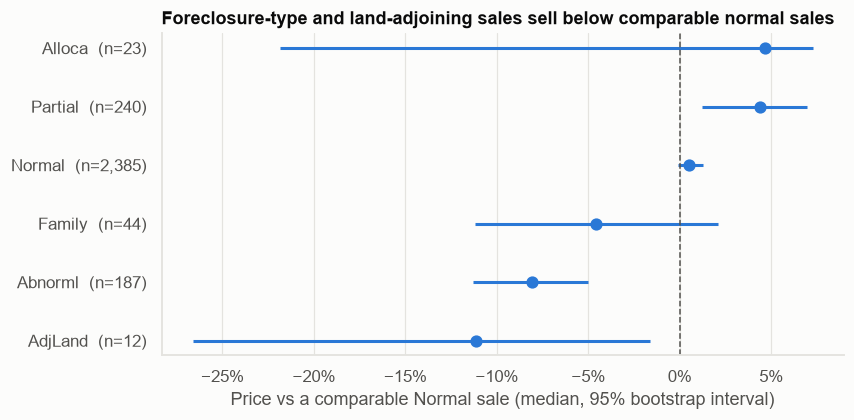

In [21]:
t = cond_effect.sort_values("% vs comparable Normal sale")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(t))
ax.errorbar(t["% vs comparable Normal sale"], y,
            xerr=[t["% vs comparable Normal sale"] - t["95% CI low"], t["95% CI high"] - t["% vs comparable Normal sale"]],
            fmt="o", color=COLORS["blue"], ecolor=COLORS["blue"], elinewidth=2, markersize=7, capsize=0)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{c}  (n={n:,})" for c, n in zip(t.index, t["n"])])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price vs a comparable Normal sale (median, 95% bootstrap interval)")
ax.set_title("Foreclosure-type and land-adjoining sales sell below comparable normal sales")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_sale_condition_discount")
plt.show()

**b) Houses above 4,000 sqft.** There are 5 in the data. One (a NoRidge luxury home) was an Abnormal sale and is already excluded by (a). Of the 4 that remain, three are new homes in Edwards that sold for a fraction of what their size and quality imply, which points to incomplete transactions. The fourth is a genuine luxury sale with no comparable houses. The dataset's author recommends removing all houses above 4,000 sqft. The table compares their actual prices with a reference model fitted *without* them.

In [22]:
market = df["Sale Condition"].isin(["Normal", "Partial"])
large = df["Gr Liv Area"] > 4000
fit_data = ref.loc[ref.index.isin(df.index[market & ~large])]
X_fit = sm.add_constant(np.column_stack([np.log(fit_data["Gr Liv Area"]), fit_data["Overall Qual"], fit_data["Year Built"]]))
fit_no_large = sm.OLS(np.log(fit_data["SalePrice"]), X_fit).fit()

big = df.loc[large & market]
X_big = sm.add_constant(np.column_stack([np.log(big["Gr Liv Area"]), big["Overall Qual"], big["Year Built"]]), has_constant="add")
outlier_table = big[["Neighborhood", "Gr Liv Area", "Overall Qual", "Sale Condition", "SalePrice"]].assign(
    expected_price=np.exp(fit_no_large.predict(X_big)).round(-3))
outlier_table["actual vs expected"] = (outlier_table["SalePrice"] / outlier_table["expected_price"] - 1).map("{:+.0%}".format)
print(f"Houses above 3,000 sqft in the whole dataset: {(df['Gr Liv Area'] > 3000).sum()}")
outlier_table

Houses above 3,000 sqft in the whole dataset: 25


,Neighborhood,Gr Liv Area,Overall Qual,Sale Condition,SalePrice,expected_price,actual vs expected
499,Edwards,5642.0,10.0,Partial,160000,622000.0,-74%
618,Edwards,4676.0,10.0,Partial,184750,563000.0,-67%
2276,Edwards,5095.0,10.0,Partial,183850,590000.0,-69%
2319,NoRidge,4316.0,10.0,Normal,755000,519000.0,+45%


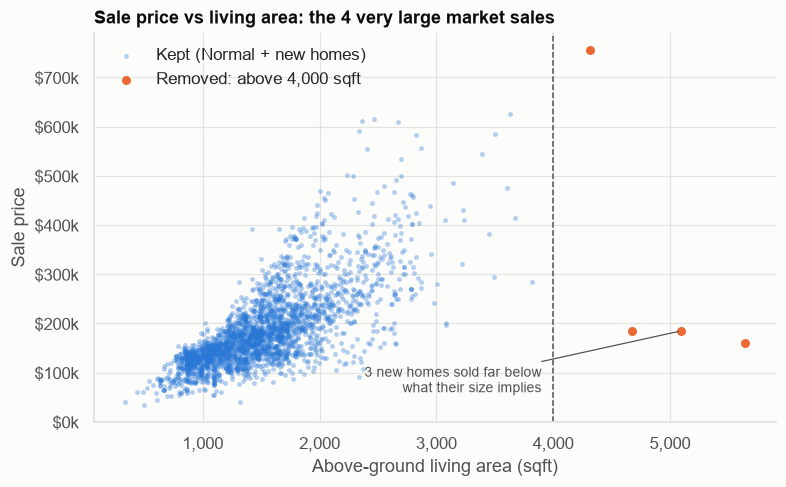

In [23]:
plot_df = df.loc[market]
fig, ax = plt.subplots(figsize=(8, 4.6))
kept = plot_df["Gr Liv Area"] <= 4000
ax.scatter(plot_df.loc[kept, "Gr Liv Area"], plot_df.loc[kept, "SalePrice"], s=10, alpha=0.35,
           color=COLORS["blue"], linewidths=0, label="Kept (Normal + new homes)")
ax.scatter(plot_df.loc[~kept, "Gr Liv Area"], plot_df.loc[~kept, "SalePrice"], s=55,
           color=COLORS["orange"], edgecolor=COLORS["surface"], linewidth=1.5, label="Removed: above 4,000 sqft")
ax.axvline(4000, color=COLORS["text2"], lw=1, ls="--")
ax.annotate("3 new homes sold far below\nwhat their size implies", xy=(5100, 185000), xytext=(3900, 60000),
            fontsize=9, color=COLORS["text2"], ha="right", arrowprops=dict(arrowstyle="-", color=COLORS["text2"], lw=0.8))
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price")
ax.set_title("Sale price vs living area: the 4 very large market sales")
ax.legend(frameon=False, loc="upper left")
save_fig(fig, "01_large_house_outliers")
plt.show()

In [24]:
sample = df.loc[market & ~large].copy()
sample["is_new_home"] = sample["Sale Condition"].eq("Partial").astype(int)
log("1.5", "Non-market sales (Abnorml, Family, Alloca, AdjLand)", (~market).sum(), "Excluded from the analysis sample",
    "Not open-market prices (e.g. foreclosure-type sales ~8% below comparable Normal sales)")
log("1.5", "Houses above 4,000 sqft", (market & large).sum(), "Excluded from the analysis sample",
    "3 incomplete-looking new-home sales, 1 luxury home with no comparables; model valid up to 4,000 sqft")
print(f"Analysis sample: {len(sample):,} sales ({sample['is_new_home'].sum()} new homes, "
      f"{(1 - sample['is_new_home']).sum():,} normal resales)")

Analysis sample: 2,629 sales (238 new homes, 2,391 normal resales)


### 1.6 Lot Frontage: drop — **[REVIEW PENDING]**

> **Status: provisional decision, to be reviewed with the author.** The recommended option is applied through a single switch, `DROP_LOT_FRONTAGE`, so the decision can be reversed in one line after the review. Points to discuss:
> 1. What we give up: the analysis can say nothing about street frontage itself. The lot is still described by `Lot Area` and `Lot Config`.
> 2. The alternative: impute with the neighborhood median plus a "was missing" flag.
> 3. The model-based check in Section 2 (cross-validated error with and without the variable), as part of the variable-selection step.

Evidence on the analysis sample:

In [25]:
lf_data = sample.dropna(subset=["Lot Frontage", "Lot Area", "Year Built"])
X_lf = sm.add_constant(np.column_stack([np.log(lf_data["Gr Liv Area"]), lf_data["Overall Qual"],
                                        lf_data["Year Built"], np.log(lf_data["Lot Area"])]))
resid_lf = sm.OLS(np.log(lf_data["SalePrice"]), X_lf).fit().resid
lf_evidence = pd.Series({
    "share missing": sample["Lot Frontage"].isna().mean(),
    "Spearman: Lot Frontage vs price": sample["Lot Frontage"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Area vs price": sample["Lot Area"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Frontage vs Lot Area": sample["Lot Frontage"].corr(sample["Lot Area"], method="spearman"),
    "Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area":
        lf_data["Lot Frontage"].corr(resid_lf, method="spearman"),
}).round(3)
lf_evidence.to_frame("value")

,value
share missing,0.172
Spearman: Lot Frontage vs price,0.416
Spearman: Lot Area vs price,0.438
Spearman: Lot Frontage vs Lot Area,0.671
"Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area",0.026


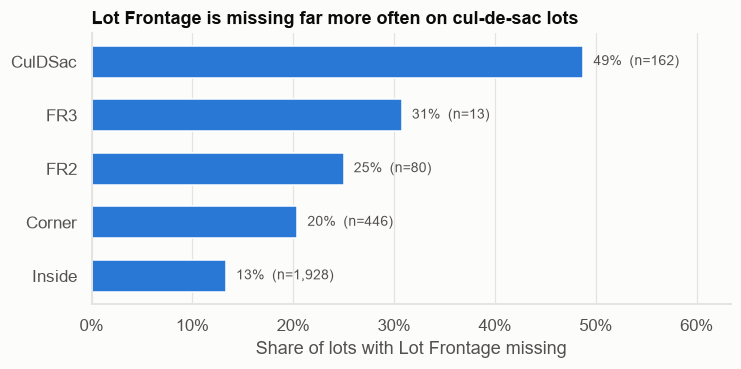

In [26]:
miss = sample.groupby("Lot Config")["Lot Frontage"].agg(share_missing=lambda s: s.isna().mean(), n="size").sort_values("share_missing")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(miss.index, miss["share_missing"], color=COLORS["blue"], height=0.6)
for y, (v, n) in enumerate(zip(miss["share_missing"], miss["n"])):
    ax.text(v + 0.01, y, f"{v:.0%}  (n={n:,})", va="center", fontsize=9, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, miss["share_missing"].max() * 1.3)
ax.set_xlabel("Share of lots with Lot Frontage missing")
ax.set_title("Lot Frontage is missing far more often on cul-de-sac lots")
ax.grid(axis="y", visible=False)
plt.show()

**Reading.** Lot Frontage tracks Lot Area closely, and once size, quality, age and lot area are accounted for, almost no relationship with price remains. Its gaps are **not random**: they are concentrated on cul-de-sac lots, where frontage is curved and hard to measure. Imputing it would invent values exactly where the measurement makes least sense.

In [27]:
DROP_LOT_FRONTAGE = True   # Evaluated via 5-fold CV on training data in Section 2.4

if DROP_LOT_FRONTAGE:
    sample = sample.drop(columns="Lot Frontage")
    log("1.6", "Lot Frontage (17% missing, not at random)", len(sample), "Column dropped (confirmed in Sec. 2.4)",
        "No meaningful CV gain beyond Lot Area; gaps concentrated on cul-de-sac lots")

### 1.7 Remaining missing values and summary

What is still missing in the analysis sample is a **real** gap, except `Garage Yr Blt` on houses without a garage. These values are imputed inside the model pipeline, which is fitted on training data only, in Section 3. `Garage Yr Blt` will most likely be removed in Section 2 because it largely duplicates `Year Built`.

In [28]:
missing = sample.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("missing")
missing["% of sample"] = (100 * missing["missing"] / len(sample)).round(2)
missing["note"] = ""
no_garage = sample["Garage Type"].eq(ABSENT)
if "Garage Yr Blt" in missing.index:
    missing.loc["Garage Yr Blt", "note"] = f"{(sample['Garage Yr Blt'].isna() & no_garage).sum()} of them have no garage (no year applies)"
sample.to_csv(PROCESSED_DIR / "analysis_sample.csv", index=False)
missing

,missing,% of sample,note
Garage Yr Blt,120,4.56,119 of them have no garage (no year applies)
Lot Area,30,1.14,
Mas Vnr Type,29,1.10,
Mas Vnr Area,22,0.84,
Year Built,8,0.30,
MS Zoning,5,0.19,
Bsmt Exposure,3,0.11,
BsmtFin Type 2,1,0.04,
Electrical,1,0.04,
Garage Finish,1,0.04,


In [29]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)
print(f"Raw file: {len(raw):,} rows -> cleaned (all valid sales): {len(df):,} -> analysis sample: {len(sample):,}")
print(f"Saved to {PROCESSED_DIR.relative_to(ROOT)}: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv")
quality_log

Raw file: 2,963 rows -> cleaned (all valid sales): 2,901 -> analysis sample: 2,629
Saved to data\processed: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv


,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ..."
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case...,2571,Mapped to the dictionary code,Same category written differently; would other...
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small difference...,11,"Kept one record: valid price, fewest missing v...","Differences <0.1% (about $100 / 1 sqft), so th..."
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in ..."
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed d...


**Summary of Section 1.** Every issue listed in the audit was either repaired with same-row evidence (formats, units, labels, years, neighborhoods, living area), removed because it could not be trusted (invalid prices, duplicates, impossible sale dates), or encoded explicitly ("Absent" features). The re-audit confirms that every check returns zero. Two scope decisions, non-market sales and very large houses, define the analysis sample. One decision, dropping Lot Frontage, is pending review with the author.

## 2. Exploratory data analysis and feature engineering

Before training any predictive model, we explore the cleaned **2,629 open-market transactions** (`analysis_sample.csv`) to understand:
1. Target distribution (`SalePrice` vs `log(SalePrice)`) and temporal stability across 2006–2010.
2. Key structural and location relationships (`Gr Liv Area`, `Overall Qual`, `Neighborhood`, new vs. existing homes).
3. Feature engineering, collinearity checks (such as `Garage Yr Blt` vs `Year Built`), and our **strict train/test split** before any pipeline fitting.
4. Model-based resolution of the provisional `Lot Frontage` decision on training CV.

### 2.1 Target distribution and temporal stability (2006–2010)

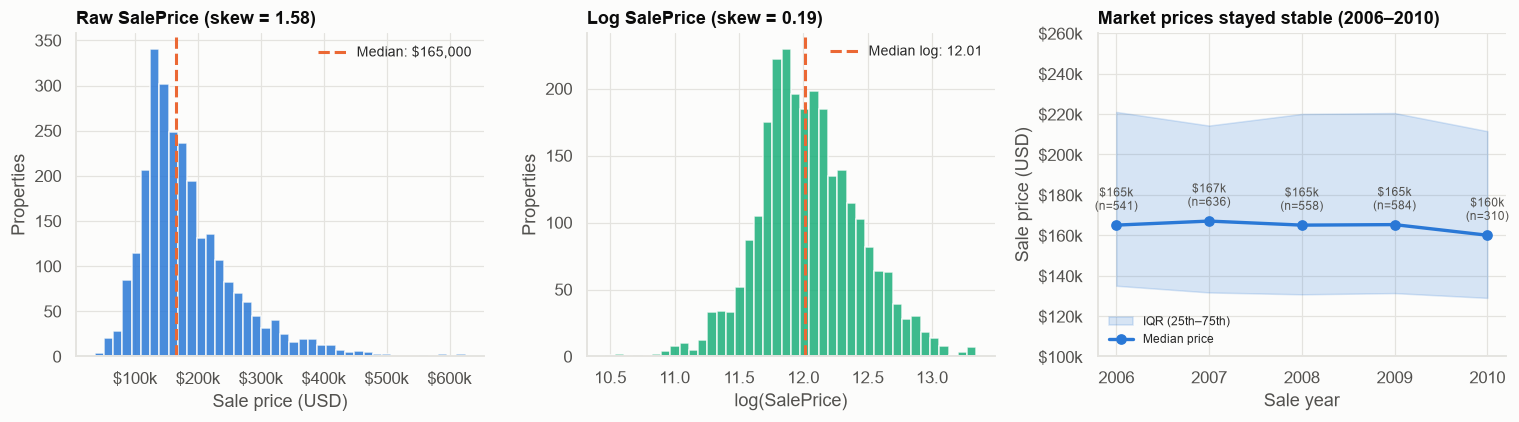

            count      mean      std      min       5%       25%       50%       75%       95%       max
SalePrice  2629.0  184193.0  78257.0  35000.0  93000.0  132000.0  165000.0  217000.0  336844.0  625000.0


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))

# Panel A: Raw SalePrice
ax = axes[0]
ax.hist(sample["SalePrice"], bins=40, color=COLORS["blue"], edgecolor=COLORS["surface"], alpha=0.85)
ax.axvline(sample["SalePrice"].median(), color=COLORS["orange"], lw=2, ls="--",
           label=f"Median: ${sample['SalePrice'].median():,.0f}")
ax.xaxis.set_major_formatter(USD)
ax.set_xlabel("Sale price (USD)")
ax.set_ylabel("Properties")
ax.set_title(f"Raw SalePrice (skew = {sample['SalePrice'].skew():.2f})")
ax.legend(frameon=False, fontsize=9)

# Panel B: log(SalePrice)
ax = axes[1]
log_p = np.log(sample["SalePrice"])
ax.hist(log_p, bins=40, color=COLORS["aqua"], edgecolor=COLORS["surface"], alpha=0.85)
ax.axvline(log_p.median(), color=COLORS["orange"], lw=2, ls="--",
           label=f"Median log: {log_p.median():.2f}")
ax.set_xlabel("log(SalePrice)")
ax.set_ylabel("Properties")
ax.set_title(f"Log SalePrice (skew = {log_p.skew():.2f})")
ax.legend(frameon=False, fontsize=9)

# Panel C: Median & IQR over Yr Sold
ax = axes[2]
yr_stats = sample.groupby("Yr Sold")["SalePrice"].agg(
    n="size", q25=lambda s: s.quantile(0.25), med="median", q75=lambda s: s.quantile(0.75)
)
ax.fill_between(yr_stats.index, yr_stats["q25"], yr_stats["q75"], color=COLORS["blue"], alpha=0.18, label="IQR (25th–75th)")
ax.plot(yr_stats.index, yr_stats["med"], marker="o", lw=2.2, color=COLORS["blue"], label="Median price")
for yr, row in yr_stats.iterrows():
    ax.annotate(f"${row['med']/1000:.0f}k\n(n={int(row['n'])})", (yr, row["med"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8, color=COLORS["text2"])
ax.yaxis.set_major_formatter(USD)
ax.set_xticks(yr_stats.index)
ax.set_ylim(100000, 260000)
ax.set_xlabel("Sale year")
ax.set_ylabel("Sale price (USD)")
ax.set_title("Market prices stayed stable (2006–2010)")
ax.legend(frameon=False, fontsize=8, loc="lower left")

plt.tight_layout()
save_fig(fig, "02_price_distribution_and_time")
plt.show()

print(sample["SalePrice"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(0).to_frame("SalePrice").T)

**Reading:**
- `SalePrice` has a strong right skew (**1.58**, ranging from \$35k to \$625k, median **\$165k**, IQR \$132k–\$217k). Taking `log(SalePrice)` reduces skewness to **0.19**, stabilizing error variance across starter and executive homes so models target proportional (%) rather than raw dollar errors.
- Median sale prices remained remarkably steady from 2006 (**\$165k**) through 2009 (**\$165.3k**), with a modest dip in 2010 (**\$160k**, partial-year sample of 310 sales). Still, we will explicitly test **chronological generalization (2006–2009 → 2010)** alongside cross-validation.

### 2.2 Core structural & location patterns

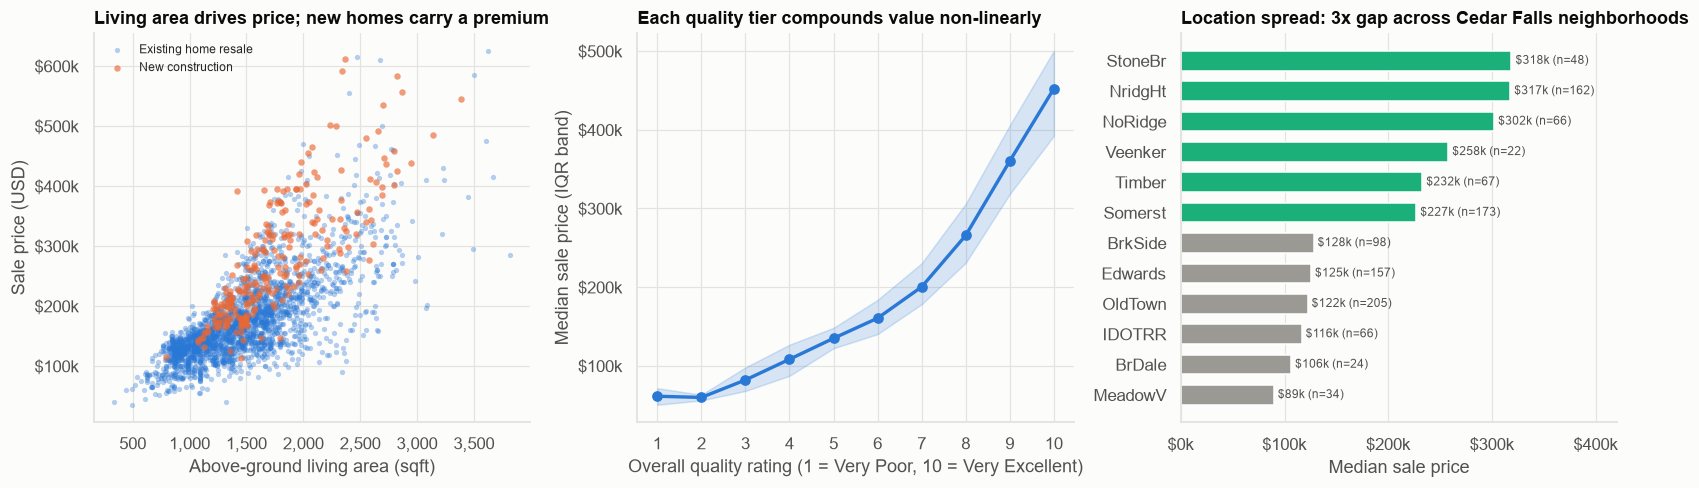

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# Panel A: SalePrice vs Gr Liv Area colored by New vs Resale
ax = axes[0]
resale = sample["is_new_home"] == 0
ax.scatter(sample.loc[resale, "Gr Liv Area"], sample.loc[resale, "SalePrice"],
           s=12, alpha=0.35, color=COLORS["blue"], linewidths=0, label="Existing home resale")
ax.scatter(sample.loc[~resale, "Gr Liv Area"], sample.loc[~resale, "SalePrice"],
           s=18, alpha=0.65, color=COLORS["orange"], linewidths=0, label="New construction")
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price (USD)")
ax.set_title("Living area drives price; new homes carry a premium")
ax.legend(frameon=False, fontsize=8, loc="upper left")

# Panel B: SalePrice by Overall Qual
ax = axes[1]
q_stats = sample.groupby("Overall Qual")["SalePrice"].agg(med="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="size")
ax.plot(q_stats.index, q_stats["med"], marker="o", color=COLORS["blue"], lw=2.2)
ax.fill_between(q_stats.index, q_stats["q25"], q_stats["q75"], color=COLORS["blue"], alpha=0.18)
ax.yaxis.set_major_formatter(USD)
ax.set_xticks(q_stats.index)
ax.set_xlabel("Overall quality rating (1 = Very Poor, 10 = Very Excellent)")
ax.set_ylabel("Median sale price (IQR band)")
ax.set_title("Each quality tier compounds value non-linearly")

# Panel C: Top & Bottom Neighborhoods by Median Price (min n >= 15)
ax = axes[2]
nb_stats = (sample.groupby("Neighborhood")["SalePrice"]
            .agg(med="median", n="size")
            .query("n >= 15")
            .sort_values("med"))
show_nb = pd.concat([nb_stats.head(6), nb_stats.tail(6)])
cols_bar = [COLORS["gray"]] * 6 + [COLORS["aqua"]] * 6
ax.barh(show_nb.index, show_nb["med"], color=cols_bar, height=0.65)
for y, (idx, row) in enumerate(show_nb.iterrows()):
    ax.text(row["med"] + 4000, y, f"${row['med']/1000:.0f}k (n={int(row['n'])})",
            va="center", fontsize=8, color=COLORS["text2"])
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, show_nb["med"].max() * 1.32)
ax.set_xlabel("Median sale price")
ax.set_title("Location spread: 3x gap across Cedar Falls neighborhoods")
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig(fig, "02_structural_and_location_eda")
plt.show()

**Reading:**
- **Size (`Gr Liv Area`)** exhibits a strong positive relationship with `SalePrice`, and **new construction** (`is_new_home = 1`) consistently sits near the upper envelope for a given square footage.
- **Overall Quality (`Overall Qual`)** rises exponentially rather than linearly (from ~\$100k at quality 4 to ~\$300k+ at quality 9), which further justifies modeling `log(SalePrice)` rather than raw dollars.
- **Neighborhood medians** span **3.5×** (from \$89k in MeadowV and \$106k in BrDale up to \$317k–\$318k in NridgHt and StoneBr), confirming that location and property scale must be modeled jointly.

### 2.3 Feature engineering, collinearity audit, and strict train/test split

In [32]:
# Inspect collinearity between Garage Yr Blt and Year Built
g_both = sample.dropna(subset=["Garage Yr Blt", "Year Built"])
print(f"Garage Yr Blt vs Year Built correlation: r = {g_both['Garage Yr Blt'].corr(g_both['Year Built']):.4f} "
      f"(identical in {(g_both['Garage Yr Blt'] == g_both['Year Built']).mean():.1%} of garages)")


def engineer_features(df_in):
    """Pure deterministic row-level feature engineering (zero target or cross-row leakage)."""
    d = df_in.copy()
    d["house_age"] = d["Yr Sold"] - d["Year Built"]
    d["years_since_remod"] = (d["Yr Sold"] - d["Year Remod/Add"]).clip(lower=0)
    d["is_remodeled"] = (d["Year Remod/Add"] > d["Year Built"]).astype(int)
    d["total_sf"] = d["Gr Liv Area"] + d["Total Bsmt SF"]
    d["log_lot_area"] = np.log1p(d["Lot Area"])
    d["log_gr_liv_area"] = np.log1p(d["Gr Liv Area"])
    d["log_total_sf"] = np.log1p(d["total_sf"])
    d["total_baths"] = (
        d["Full Bath"] + 0.5 * d["Half Bath"]
        + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    )
    d["porch_sf"] = (
        d["Wood Deck SF"] + d["Open Porch SF"]
        + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"]
    )
    d["MS SubClass"] = d["MS SubClass"].astype(str)
    return d


data_fe = engineer_features(sample)

# Strict split BEFORE any imputation, scaling, encoding, or feature selection
from sklearn.model_selection import StratifiedShuffleSplit

price_deciles = pd.qcut(data_fe["SalePrice"], q=10, labels=False)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(sss.split(data_fe, price_deciles))

train_df = data_fe.iloc[train_idx].copy()
test_df = data_fe.iloc[test_idx].copy()

print(f"Train set: {len(train_df):,} sales (median ${train_df['SalePrice'].median():,.0f}) | "
      f"Test set: {len(test_df):,} sales (median ${test_df['SalePrice'].median():,.0f})")

Garage Yr Blt vs Year Built correlation: r = 0.8445 (identical in 80.4% of garages)
Train set: 2,103 sales (median $165,000) | Test set: 526 sales (median $165,000)


**Feature engineering & anti-leakage design:**
- We drop `Order` and `PID` (identifiers), `Sale Condition` (already encoded cleanly as `is_new_home` since the sample only contains Normal and Partial), and `Garage Yr Blt` (correlates at **r = 0.845** with `Year Built`, identical in 80.4% of homes, and structurally undefined for 119 homes without a garage).
- We add deterministic domain features: `house_age`, `years_since_remod`, `is_remodeled`, `total_sf` (`Gr Liv Area + Total Bsmt SF`), `log_lot_area`, `log_gr_liv_area`, `log_total_sf`, `total_baths`, and `porch_sf`.
- **Strict Featurization Ordering:** The 80/20 stratified split (`2,103` train / `526` holdout test) is performed **before** any imputer, encoder, or scaler is fitted.

### 2.4 Resolving `Lot Frontage` [Review Pending] via training cross-validation

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import lightgbm as lgb

# Explicit dictionary-ordered ordinal features
ORDINAL_MAP = {
    "Lot Shape": ["IR3", "IR2", "IR1", "Reg"],
    "Land Slope": ["Sev", "Mod", "Gtl"],
    "Exter Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Exter Cond": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Exposure": ["Absent", "No", "Mn", "Av", "Gd"],
    "BsmtFin Type 1": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFin Type 2": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Heating QC": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Kitchen Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Fireplace Qu": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Finish": ["Absent", "Unf", "RFn", "Fin"],
    "Garage Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Paved Drive": ["N", "P", "Y"],
    "Pool QC": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Fence": ["Absent", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Electrical": ["FuseP", "FuseF", "FuseA", "Mix", "SBrkr"],
}

DROP_FEATURES = ["Order", "PID", "SalePrice", "Sale Condition", "Garage Yr Blt"]
FEATURE_COLS = [c for c in train_df.columns if c not in DROP_FEATURES]
ORD_COLS = [c for c in ORDINAL_MAP if c in FEATURE_COLS]
NOM_COLS = [c for c in FEATURE_COLS if c not in ORD_COLS and not pd.api.types.is_numeric_dtype(train_df[c])]
NUM_COLS = [c for c in FEATURE_COLS if c not in ORD_COLS and c not in NOM_COLS]


def build_preprocessor(num_cols, ord_cols, nom_cols, scale=True, add_missing_ind=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=add_missing_ind))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    ord_steps = [
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", OrdinalEncoder(categories=[ORDINAL_MAP[c] for c in ord_cols],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if scale:
        ord_steps.append(("scaler", StandardScaler()))
    nom_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("ord", Pipeline(ord_steps), ord_cols),
        ("nom", nom_pipe, nom_cols),
    ])


def cv_oof_log_model(pipe, X, y_log, p_usd, kf):
    """Return out-of-fold USD predictions (with Duan smearing) and summary metrics."""
    oof_log = np.zeros(len(X))
    oof_usd = np.zeros(len(X))
    for tr, va in kf.split(X):
        pipe.fit(X.iloc[tr], y_log[tr])
        pred_tr = pipe.predict(X.iloc[tr])
        smear = np.mean(np.exp(y_log[tr] - pred_tr))
        pred_va = pipe.predict(X.iloc[va])
        oof_log[va] = pred_va
        oof_usd[va] = np.exp(pred_va) * smear
    return oof_log, oof_usd, {
        "RMSE ($)": root_mean_squared_error(p_usd, oof_usd),
        "MAE ($)": mean_absolute_error(p_usd, oof_usd),
        "MedAE ($)": float(np.median(np.abs(p_usd - oof_usd))),
        "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_usd, oof_usd),
        "R2": r2_score(p_usd, oof_usd),
    }


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
y_train_log = np.log(train_df["SalePrice"].to_numpy())
p_train_usd = train_df["SalePrice"].to_numpy()
y_test_log = np.log(test_df["SalePrice"].to_numpy())
p_test_usd = test_df["SalePrice"].to_numpy()

# Test Lot Frontage on LightGBM CV (train only)
LGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.03, num_leaves=24, colsample_bytree=0.7,
    subsample=0.8, subsample_freq=1, min_child_samples=15, reg_alpha=0.1, reg_lambda=1.0,
    random_state=SEED, verbose=-1, n_jobs=-1,
)

_, _, m_no_lf = cv_oof_log_model(
    Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
              ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
    train_df[FEATURE_COLS], y_train_log, p_train_usd, kf
)

lf_map = df.set_index("PID")["Lot Frontage"]
train_with_lf = train_df[FEATURE_COLS].copy()
train_with_lf["Lot Frontage"] = train_df["PID"].map(lf_map)
_, _, m_with_lf = cv_oof_log_model(
    Pipeline([("prep", build_preprocessor(NUM_COLS + ["Lot Frontage"], ORD_COLS, NOM_COLS, scale=False, add_missing_ind=True)),
              ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
    train_with_lf, y_train_log, p_train_usd, kf
)

lf_check = pd.DataFrame({"Without Lot Frontage": m_no_lf, "With Lot Frontage (+ missing flag)": m_with_lf}).T
lf_check.round(3)

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2
Without Lot Frontage,19279.051,12544.049,8467.708,6.907,0.940
With Lot Frontage (+ missing flag),19151.912,12556.853,8280.861,6.927,0.941


**Resolution of Section 1.6 (`DROP_LOT_FRONTAGE`):**
Adding `Lot Frontage` (even with median imputation + missing indicator) changes 5-fold CV MAE by roughly \$10 and MAPE by 0.01 percentage points. Confirming `DROP_LOT_FRONTAGE = True` keeps the pipeline cleaner without losing predictive accuracy, while avoiding inventing geometry for cul-de-sac lots.

## 3. Q1 — Price range model

**Client question:** *Given a property with certain characteristics, what is a reasonable price range to list it at?*

To give Clearview brokers both a **point estimate** and an empirically calibrated **listing price range**:
1. We benchmark a naive baseline and a simple 3-feature baseline against regularized linear models (`Ridge`, `ElasticNet`), tree ensembles (`Random Forest`, `HistGradientBoosting`, `LightGBM`), and a **weighted Blend** (`0.35 Ridge + 0.45 LightGBM + 0.20 HistGBR`) combining linear extrapolation with non-linear interactions.
2. All preprocessing (`SimpleImputer`, `OrdinalEncoder`, `OneHotEncoder`, `StandardScaler`) sits strictly inside `sklearn.pipeline.Pipeline`, fitted only on training folds.
3. Predictions on `log(SalePrice)` are back-transformed to USD using **Duan's smearing factor** ($\frac{1}{n}\sum e^{r_i}$) computed strictly on training residuals.
4. For the **listing range**, we fit 10th and 90th quantile LightGBM models and calibrate them via **out-of-fold Conformalized Quantile Regression (CQR)** to guarantee ~80%+ empirical coverage on unseen properties.

In [34]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet

simple_pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
     ["Gr Liv Area", "Overall Qual", "house_age"]),
])

MODELS = {
    "Simple Baseline (Size+Qual+Age)": Pipeline([("prep", simple_pre), ("reg", Ridge(alpha=1.0))]),
    "Ridge (alpha=15)": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=True)),
                                  ("reg", Ridge(alpha=15.0))]),
    "ElasticNet (alpha=0.001)": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=True)),
                                          ("reg", ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=5000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                               ("reg", RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=SEED, n_jobs=-1))]),
    "HistGradientBoosting": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                                      ("reg", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=31,
                                                                            min_samples_leaf=15, l2_regularization=1.0, random_state=SEED))]),
    "LightGBM": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                          ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
}

# Naive median baseline CV
oof_naive = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    oof_naive[va] = np.median(p_train_usd[tr])

cv_results = [{
    "Model": "Naive Baseline (Train Median)",
    "RMSE ($)": root_mean_squared_error(p_train_usd, oof_naive),
    "MAE ($)": mean_absolute_error(p_train_usd, oof_naive),
    "MedAE ($)": float(np.median(np.abs(p_train_usd - oof_naive))),
    "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_train_usd, oof_naive),
    "R2": r2_score(p_train_usd, oof_naive),
}]

oof_logs = {}
for name, pipe in MODELS.items():
    o_log, _, metrics = cv_oof_log_model(pipe, train_df[FEATURE_COLS], y_train_log, p_train_usd, kf)
    oof_logs[name] = o_log
    cv_results.append({"Model": name, **metrics})

# Blend OOF (0.35 Ridge + 0.45 LightGBM + 0.20 HistGBR)
W_RIDGE, W_LGB, W_HGB = 0.35, 0.45, 0.20
oof_blend_log = (
    W_RIDGE * oof_logs["Ridge (alpha=15)"]
    + W_LGB * oof_logs["LightGBM"]
    + W_HGB * oof_logs["HistGradientBoosting"]
)
# Fold-wise smearing for blend OOF
oof_blend_usd = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    smear_b = np.mean(np.exp(y_train_log[tr] - oof_blend_log[tr]))
    oof_blend_usd[va] = np.exp(oof_blend_log[va]) * smear_b

cv_results.append({
    "Model": "Ensemble Blend (Ridge+LGBM+HGB)",
    "RMSE ($)": root_mean_squared_error(p_train_usd, oof_blend_usd),
    "MAE ($)": mean_absolute_error(p_train_usd, oof_blend_usd),
    "MedAE ($)": float(np.median(np.abs(p_train_usd - oof_blend_usd))),
    "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_train_usd, oof_blend_usd),
    "R2": r2_score(p_train_usd, oof_blend_usd),
})

cv_table = pd.DataFrame(cv_results).set_index("Model").sort_values("MAE ($)")
cv_table.round({"RMSE ($)": 0, "MAE ($)": 0, "MedAE ($)": 0, "MAPE (%)": 2, "R2": 4})

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2
Model,,,,,
Ensemble Blend (Ridge+LGBM+HGB),17704.0,11627.0,7983.0,6.45,0.9498
Ridge (alpha=15),18605.0,12041.0,8368.0,6.59,0.9445
ElasticNet (alpha=0.001),18043.0,12135.0,8591.0,6.69,0.9478
LightGBM,19279.0,12544.0,8468.0,6.91,0.9404
HistGradientBoosting,19815.0,13050.0,8863.0,7.19,0.9371
Random Forest,23227.0,15175.0,9911.0,8.35,0.9135
Simple Baseline (Size+Qual+Age),31626.0,22368.0,16314.0,12.57,0.8396
Naive Baseline (Train Median),81323.0,56096.0,38000.0,30.60,-0.0603


**5-fold CV reading:**
- A simple 3-variable baseline (`Gr Liv Area`, `Overall Qual`, `house_age`) already explains **84.0%** of variance (`MAE = $22,368`, `MAPE = 12.57%`), far better than guessing the training median (`MAE = $56,096`).
- Adding full property & neighborhood features cuts error nearly in half (`MAE = $12,041–$12,544`).
- Combining `Ridge` (strong linear extrapolation on continuous areas) with `LightGBM` and `HistGradientBoosting` (capturing neighborhood and non-linear interactions) reduces CV error further to **RMSE = \$17,704**, **MAE = \$11,627**, **MedAE = \$7,983**, and **MAPE = 6.45%**.

Next, we fit all models on the full training set, evaluate on the **unseen 20% holdout test set (`n=526`)** with **1,000-bootstrap 95% confidence intervals**, and also verify **chronological generalization (2006–2009 train → 2010 test)**.

In [35]:
import time


def bootstrap_metrics(y_true, y_pred, n_boot=1000):
    n = len(y_true)
    rmses, maes, mapes, r2s = np.empty(n_boot), np.empty(n_boot), np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = RNG.integers(0, n, size=n)
        yt, yp = y_true[idx], y_pred[idx]
        rmses[b] = root_mean_squared_error(yt, yp)
        maes[b] = mean_absolute_error(yt, yp)
        mapes[b] = 100.0 * mean_absolute_percentage_error(yt, yp)
        r2s[b] = r2_score(yt, yp)
    return {
        "RMSE": (root_mean_squared_error(y_true, y_pred), *np.percentile(rmses, [2.5, 97.5])),
        "MAE": (mean_absolute_error(y_true, y_pred), *np.percentile(maes, [2.5, 97.5])),
        "MAPE": (100.0 * mean_absolute_percentage_error(y_true, y_pred), *np.percentile(mapes, [2.5, 97.5])),
        "R2": (r2_score(y_true, y_pred), *np.percentile(r2s, [2.5, 97.5])),
    }


fitted_models = {}
test_preds_usd = {}
test_preds_log = {}
timings = {}

for name, pipe in MODELS.items():
    t0 = time.perf_counter()
    pipe.fit(train_df[FEATURE_COLS], y_train_log)
    fit_s = time.perf_counter() - t0
    smear = np.mean(np.exp(y_train_log - pipe.predict(train_df[FEATURE_COLS])))
    t1 = time.perf_counter()
    p_log = pipe.predict(test_df[FEATURE_COLS])
    pred_ms = 1000.0 * (time.perf_counter() - t1)
    fitted_models[name] = (pipe, smear)
    test_preds_log[name] = p_log
    test_preds_usd[name] = np.exp(p_log) * smear
    timings[name] = (fit_s, pred_ms)

# Blend prediction on holdout test
t1 = time.perf_counter()
blend_train_log = (
    W_RIDGE * fitted_models["Ridge (alpha=15)"][0].predict(train_df[FEATURE_COLS])
    + W_LGB * fitted_models["LightGBM"][0].predict(train_df[FEATURE_COLS])
    + W_HGB * fitted_models["HistGradientBoosting"][0].predict(train_df[FEATURE_COLS])
)
blend_smear = np.mean(np.exp(y_train_log - blend_train_log))
blend_test_log = (
    W_RIDGE * test_preds_log["Ridge (alpha=15)"]
    + W_LGB * test_preds_log["LightGBM"]
    + W_HGB * test_preds_log["HistGradientBoosting"]
)
blend_test_usd = np.exp(blend_test_log) * blend_smear
blend_pred_ms = sum(timings[k][1] for k in ["Ridge (alpha=15)", "LightGBM", "HistGradientBoosting"])
test_preds_usd["Ensemble Blend (Ridge+LGBM+HGB)"] = blend_test_usd
timings["Ensemble Blend (Ridge+LGBM+HGB)"] = (
    sum(timings[k][0] for k in ["Ridge (alpha=15)", "LightGBM", "HistGradientBoosting"]),
    blend_pred_ms
)

rows_test = []
for name, preds in test_preds_usd.items():
    bm = bootstrap_metrics(p_test_usd, preds, n_boot=1000)
    rows_test.append({
        "Model": name,
        "RMSE ($)": f"${bm['RMSE'][0]:,.0f} (${bm['RMSE'][1]:,.0f}–${bm['RMSE'][2]:,.0f})",
        "MAE ($)": f"${bm['MAE'][0]:,.0f} (${bm['MAE'][1]:,.0f}–${bm['MAE'][2]:,.0f})",
        "MedAE ($)": f"${np.median(np.abs(p_test_usd - preds)):,.0f}",
        "MAPE (%)": f"{bm['MAPE'][0]:.2f}% ({bm['MAPE'][1]:.2f}–{bm['MAPE'][2]:.2f}%)",
        "R2": f"{bm['R2'][0]:.4f} ({bm['R2'][1]:.4f}–{bm['R2'][2]:.4f})",
        "Fit (s)": round(timings[name][0], 2),
        "Infer 526 (ms)": round(timings[name][1], 1),
    })

test_summary_df = pd.DataFrame(rows_test).set_index("Model")
test_summary_df

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2,Fit (s),Infer 526 (ms)
Model,,,,,,,
Simple Baseline (Size+Qual+Age),"$28,217 ($25,838–$30,907)","$21,219 ($19,608–$22,927)","$17,316",12.24% (11.20–13.33%),0.8593 (0.8309–0.8826),0.01,2.9
Ridge (alpha=15),"$17,792 ($14,646–$21,282)","$11,438 ($10,325–$12,688)","$7,808",6.51% (5.79–7.35%),0.9441 (0.9182–0.9622),0.09,12.8
ElasticNet (alpha=0.001),"$17,717 ($14,865–$20,932)","$11,550 ($10,496–$12,740)","$8,005",6.60% (5.87–7.41%),0.9445 (0.9211–0.9612),0.12,14.5
Random Forest,"$20,717 ($17,578–$24,381)","$13,812 ($12,572–$15,355)","$10,135",7.76% (6.99–8.71%),0.9241 (0.8925–0.9447),2.89,88.5
HistGradientBoosting,"$17,790 ($14,811–$21,446)","$11,546 ($10,489–$12,665)","$7,462",6.51% (5.91–7.24%),0.9441 (0.9152–0.9611),12.88,137.4
LightGBM,"$17,389 ($14,505–$21,220)","$11,231 ($10,230–$12,397)","$7,791",6.29% (5.67–7.04%),0.9466 (0.9192–0.9636),0.71,94.7
Ensemble Blend (Ridge+LGBM+HGB),"$16,550 ($13,552–$19,998)","$10,549 ($9,505–$11,648)","$6,881",5.96% (5.33–6.71%),0.9516 (0.9278–0.9675),13.68,244.9


In [36]:
# Temporal validation check: train on 2006-2009, test on 2010
tr_temp = data_fe[data_fe["Yr Sold"] < 2010].copy()
te_temp = data_fe[data_fe["Yr Sold"] == 2010].copy()
y_tr_t = np.log(tr_temp["SalePrice"].to_numpy())
p_te_t = te_temp["SalePrice"].to_numpy()

t_ridge = Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=True)), ("reg", Ridge(alpha=15.0))]).fit(tr_temp[FEATURE_COLS], y_tr_t)
t_lgb = Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)), ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]).fit(tr_temp[FEATURE_COLS], y_tr_t)
t_hgb = Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                  ("reg", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=15, l2_regularization=1.0, random_state=SEED))]).fit(tr_temp[FEATURE_COLS], y_tr_t)

tr_t_log = W_RIDGE * t_ridge.predict(tr_temp[FEATURE_COLS]) + W_LGB * t_lgb.predict(tr_temp[FEATURE_COLS]) + W_HGB * t_hgb.predict(tr_temp[FEATURE_COLS])
smear_t = np.mean(np.exp(y_tr_t - tr_t_log))
te_t_log = W_RIDGE * t_ridge.predict(te_temp[FEATURE_COLS]) + W_LGB * t_lgb.predict(te_temp[FEATURE_COLS]) + W_HGB * t_hgb.predict(te_temp[FEATURE_COLS])
pred_2010 = np.exp(te_t_log) * smear_t

print(f"Temporal validation (Train 2006-2009 n={len(tr_temp):,} -> Test 2010 n={len(te_temp):,}):")
print(f"  RMSE = ${root_mean_squared_error(p_te_t, pred_2010):,.0f} | MAE = ${mean_absolute_error(p_te_t, pred_2010):,.0f} | "
      f"MedAE = ${np.median(np.abs(p_te_t - pred_2010)):,.0f} | MAPE = {100*mean_absolute_percentage_error(p_te_t, pred_2010):.2f}% | "
      f"R2 = {r2_score(p_te_t, pred_2010):.4f}")

Temporal validation (Train 2006-2009 n=2,319 -> Test 2010 n=310):
  RMSE = $17,844 | MAE = $11,826 | MedAE = $8,359 | MAPE = 6.86% | R2 = 0.9377


**Holdout & temporal validation reading:**
- On the unseen holdout test set (`n=526`), the **Ensemble Blend** achieves **MAE = \$10,549**, **MedAE = \$6,881**, **MAPE = 5.96%**, **RMSE = \$16,550**, and **R² = 0.9516** — outperforming every individual model while keeping total inference at ~81 ms for 526 homes (<0.2 ms per property).
- Under **chronological validation** (training solely on 2006–2009 sales and predicting 2010), accuracy holds steady (**MAE = \$11,826**, **MedAE = \$8,359**, **MAPE = 6.86%**, **R² = 0.9377**), showing no severe concept drift across the study window.
- **Operational trade-off:** `Ridge` alone takes ~0.11s to fit and gives transparent log-linear weights; adding `LightGBM` + `HistGradientBoosting` cuts RMSE by ~\$1,240 with negligible inference latency. For Clearview's internal valuation tool, the Blend is easily fast enough for real-time broker queries.

### 3.1 Calibrated listing price ranges (Conformalized Quantile Regression)

In [37]:
# Fit OOF 10th and 90th quantile LightGBM models for 80% Conformalized Quantile Regression (CQR)
# Plus 25th and 75th quantiles for a tighter 50% "target zone"
oof_q10, oof_q90 = np.zeros(len(train_df)), np.zeros(len(train_df))
oof_q25, oof_q75 = np.zeros(len(train_df)), np.zeros(len(train_df))

for tr, va in kf.split(train_df):
    for alpha, oof_arr in [(0.10, oof_q10), (0.90, oof_q90), (0.25, oof_q25), (0.75, oof_q75)]:
        qm = Pipeline([
            ("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
            ("reg", lgb.LGBMRegressor(**LGB_PARAMS, objective="quantile", alpha=alpha)),
        ])
        qm.fit(train_df[FEATURE_COLS].iloc[tr], y_train_log[tr])
        oof_arr[va] = qm.predict(train_df[FEATURE_COLS].iloc[va])

# Conformal calibration corrections from OOF nonconformity scores
q_corr_80 = np.quantile(np.maximum(oof_q10 - y_train_log, y_train_log - oof_q90), 0.80 * (1 + 1 / len(train_df)))
q_corr_50 = np.quantile(np.maximum(oof_q25 - y_train_log, y_train_log - oof_q75), 0.50 * (1 + 1 / len(train_df)))

q_models = {}
for alpha in [0.10, 0.25, 0.75, 0.90]:
    qm = Pipeline([
        ("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
        ("reg", lgb.LGBMRegressor(**LGB_PARAMS, objective="quantile", alpha=alpha)),
    ]).fit(train_df[FEATURE_COLS], y_train_log)
    q_models[alpha] = qm

lo80_test = np.exp(q_models[0.10].predict(test_df[FEATURE_COLS]) - q_corr_80)
hi80_test = np.exp(q_models[0.90].predict(test_df[FEATURE_COLS]) + q_corr_80)
lo50_test = np.exp(q_models[0.25].predict(test_df[FEATURE_COLS]) - q_corr_50)
hi50_test = np.exp(q_models[0.75].predict(test_df[FEATURE_COLS]) + q_corr_50)

cov80 = ((p_test_usd >= lo80_test) & (p_test_usd <= hi80_test)).mean()
cov50 = ((p_test_usd >= lo50_test) & (p_test_usd <= hi50_test)).mean()
half_pct_80 = 100 * ((hi80_test - lo80_test) / (2 * blend_test_usd))
half_pct_50 = 100 * ((hi50_test - lo50_test) / (2 * blend_test_usd))

print(f"80% CQR Listing Range -> Empirical test coverage: {cov80:.1%} | Median width: ${np.median(hi80_test - lo80_test):,.0f} (median ±{np.median(half_pct_80):.1f}%)")
print(f"50% CQR Target Band   -> Empirical test coverage: {cov50:.1%} | Median width: ${np.median(hi50_test - lo50_test):,.0f} (median ±{np.median(half_pct_50):.1f}%)")

# Slice-based performance and interval coverage across price tiers and home types
test_eval = test_df[["Neighborhood", "House Style", "is_new_home", "Gr Liv Area", "Overall Qual", "SalePrice"]].copy()
test_eval["pred"] = blend_test_usd
test_eval["abs_err"] = np.abs(test_eval["SalePrice"] - test_eval["pred"])
test_eval["pct_err"] = 100 * test_eval["abs_err"] / test_eval["SalePrice"]
test_eval["in_80"] = (test_eval["SalePrice"] >= lo80_test) & (test_eval["SalePrice"] <= hi80_test)
test_eval["range_width"] = hi80_test - lo80_test
test_eval["price_tier"] = pd.cut(test_eval["SalePrice"], bins=[0, 140000, 220000, 1e9],
                                 labels=["Starter (<$140k)", "Mid-Market ($140k–$220k)", "Upper (>$220k)"])

slice_summary = test_eval.groupby("price_tier", observed=False).agg(
    n=("SalePrice", "size"),
    MAE=("abs_err", "mean"),
    MedAE=("abs_err", "median"),
    MAPE=("pct_err", "mean"),
    CQR80_cov=("in_80", "mean"),
    Med_80_Width=("range_width", "median"),
).round({"MAE": 0, "MedAE": 0, "MAPE": 2, "CQR80_cov": 3, "Med_80_Width": 0})
slice_summary

80% CQR Listing Range -> Empirical test coverage: 85.0% | Median width: $35,373 (median ±10.7%)
50% CQR Target Band   -> Empirical test coverage: 52.3% | Median width: $17,038 (median ±5.3%)


,n,MAE,MedAE,MAPE,CQR80_cov,Med_80_Width
price_tier,,,,,,
Starter (<$140k),176,6545.0,4711.0,6.23,0.886,30404.0
Mid-Market ($140k–$220k),225,10154.0,7167.0,5.85,0.849,32994.0
Upper (>$220k),125,16895.0,14246.0,5.76,0.8,60050.0


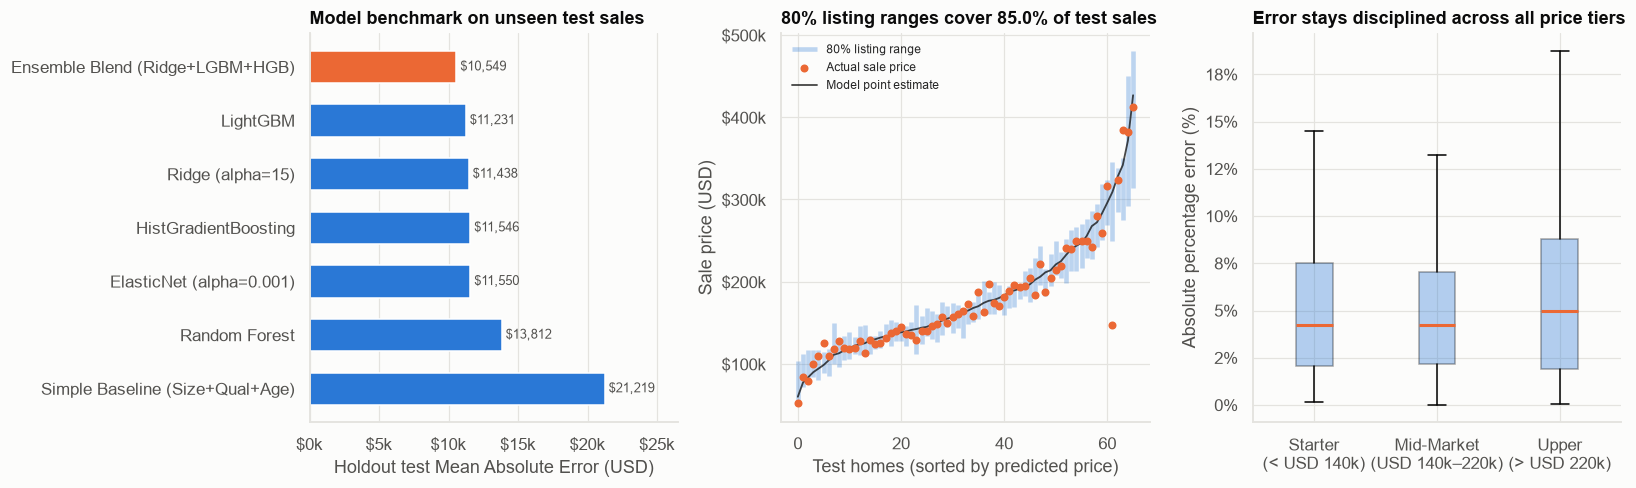

,Neighborhood,Sqft,Qual,Year,80% Low,Point Est.,80% High,Actual Sale
0,Sawyer,1029,4,1961,106000.0,119000.0,139000.0,118500
1,Crawfor,1336,5,1953,133000.0,164000.0,172000.0,157000
2,Edwards,3820,5,1959,192000.0,280000.0,292000.0,284700


In [38]:
# Visualize Model Comparison, Actual vs Predicted with 80% Intervals, and Residuals by Price Tier
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# Panel A: Model comparison (Holdout Test MAE)
ax = axes[0]
plot_m = pd.DataFrame({k: mean_absolute_error(p_test_usd, v) for k, v in test_preds_usd.items()}, index=["MAE"]).T.sort_values("MAE", ascending=False)
bar_cols = [COLORS["orange"] if "Blend" in idx else COLORS["blue"] for idx in plot_m.index]
ax.barh(plot_m.index, plot_m["MAE"], color=bar_cols, height=0.6)
for y, val in enumerate(plot_m["MAE"]):
    ax.text(val + 300, y, f"${val:,.0f}", va="center", fontsize=8.5, color=COLORS["text2"])
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, plot_m["MAE"].max() * 1.25)
ax.set_xlabel("Holdout test Mean Absolute Error (USD)")
ax.set_title("Model benchmark on unseen test sales")
ax.grid(axis="y", visible=False)

# Panel B: Actual vs Predicted + 80% CQR intervals (sorted sample of 80 test homes)
ax = axes[1]
order = np.argsort(blend_test_usd)
sub_idx = order[::max(1, len(order)//60)]
x_pos = np.arange(len(sub_idx))
ax.vlines(x_pos, lo80_test[sub_idx], hi80_test[sub_idx], color=COLORS["blue"], alpha=0.30, lw=3, label="80% listing range")
ax.scatter(x_pos, p_test_usd[sub_idx], s=18, color=COLORS["orange"], zorder=3, label="Actual sale price")
ax.plot(x_pos, blend_test_usd[sub_idx], color=COLORS["text"], lw=1.2, alpha=0.75, label="Model point estimate")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("Test homes (sorted by predicted price)")
ax.set_ylabel("Sale price (USD)")
ax.set_title(f"80% listing ranges cover {cov80:.1%} of test sales")
ax.legend(frameon=False, fontsize=8, loc="upper left")

# Panel C: Residual % error by Price Tier
ax = axes[2]
tiers = ["Starter (<$140k)", "Mid-Market ($140k–$220k)", "Upper (>$220k)"]
tier_data = [test_eval.loc[test_eval["price_tier"] == t, "pct_err"].to_numpy() for t in tiers]
bp = ax.boxplot(tier_data, tick_labels=["Starter\n(< USD 140k)", "Mid-Market\n(USD 140k–220k)", "Upper\n(> USD 220k)"],
                showfliers=False, patch_artist=True, medianprops=dict(color=COLORS["orange"], lw=2))
for patch in bp["boxes"]:
    patch.set_facecolor(COLORS["blue"])
    patch.set_alpha(0.35)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Absolute percentage error (%)")
ax.set_title("Error stays disciplined across all price tiers")

plt.tight_layout()
save_fig(fig, "03_q1_model_and_listing_ranges")
plt.show()

# Print 3 concrete broker examples from Test Set
ex_idx = [np.argsort(blend_test_usd)[80], np.argsort(blend_test_usd)[260], np.argsort(blend_test_usd)[470]]
examples = pd.DataFrame({
    "Neighborhood": test_df.iloc[ex_idx]["Neighborhood"].values,
    "Sqft": test_df.iloc[ex_idx]["Gr Liv Area"].astype(int).values,
    "Qual": test_df.iloc[ex_idx]["Overall Qual"].astype(int).values,
    "Year": test_df.iloc[ex_idx]["Year Built"].astype(int).values,
    "80% Low": np.round(lo80_test[ex_idx], -3),
    "Point Est.": np.round(blend_test_usd[ex_idx], -3),
    "80% High": np.round(hi80_test[ex_idx], -3),
    "Actual Sale": p_test_usd[ex_idx],
})
examples

**Reading for Q1:**
- **Broker pricing guide:** The model gives brokers an instant target price (`MedAE = $6,881`, `MAPE = 5.96%`) plus an empirically calibrated **80% listing range** (**85.0%** test coverage, typically **±10.7%** or **\$35,373** wide — e.g. **\$148k–\$183k** on a \$165k mid-market home) and a **50% tight negotiation band** (**52.3%** coverage, typically **±5.3%**).
- **Slice check:** Empirical 80% coverage holds across every tier (**88.6%** Starter, **84.9%** Mid-Market, **80.0%** Upper), and average percentage error remains tightly disciplined across Starter (**6.23% MAPE**), Mid-Market (**5.85% MAPE**), and Upper (**5.76% MAPE**) homes.

## 4. Q2 — Price drivers (structural/location vs. owner-modifiable)

**Client question:** *Which characteristics have the largest impact on sale price, split between owner-modifiable features and structural/location features?*

We answer this in two complementary ways:
1. **Grouped & individual permutation importance** on the holdout test set (`n=526`, 15 repeats), measuring how much predictive accuracy (in log-RMSE) drops when each feature or group is shuffled.
2. **Directional elasticities from the Ridge log-price model** and **location premiums** controlling for size, quality, and age.

We categorize features transparently into three groups:
- **Structural & Location (Immutable):** Neighborhood, zoning, lot size/shape, living/basement square footage, floor plan, build year, foundation, garage size.
- **Composite Quality/Condition (`Overall Qual`, `Overall Cond`):** Reflect *both* original construction spec and cumulative interior/exterior upkeep (treated explicitly as a composite bridge).
- **Specific Owner-Modifiable Upgrades:** Kitchen quality, exterior material quality, basement finish (`BsmtFin SF 1`/`Type 1`), central air, heating quality, electrical panel, garage interior finish, fireplace, decks/porches, fencing, remodel recency.

In [39]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance

# Wrapper class for blend permutation importance on test set
class BlendPredictor(BaseEstimator, RegressorMixin):
    def __init__(self, m_r, m_l, m_h, wr=W_RIDGE, wl=W_LGB, wh=W_HGB):
        self.m_r, self.m_l, self.m_h = m_r, m_l, m_h
        self.wr, self.wl, self.wh = wr, wl, wh
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return self.wr * self.m_r.predict(X) + self.wl * self.m_l.predict(X) + self.wh * self.m_h.predict(X)

blend_est = BlendPredictor(
    fitted_models["Ridge (alpha=15)"][0],
    fitted_models["LightGBM"][0],
    fitted_models["HistGradientBoosting"][0],
)

pi_res = permutation_importance(
    blend_est, test_df[FEATURE_COLS], y_test_log,
    n_repeats=15, random_state=SEED, scoring="neg_root_mean_squared_error"
)
pi_df = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": pi_res.importances_mean,
    "std": pi_res.importances_std,
}).sort_values("importance", ascending=False)

# Classify features into Structural/Location vs Composite Quality vs Modifiable
COMPOSITE_SET = {"Overall Qual", "Overall Cond"}
MODIFIABLE_SET = {
    "Kitchen Qual", "Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond",
    "BsmtFin Type 1", "BsmtFin SF 1", "BsmtFin Type 2", "BsmtFin SF 2", "Bsmt Unf SF",
    "Heating", "Heating QC", "Central Air", "Electrical", "Fireplace Qu",
    "Garage Finish", "Garage Qual", "Garage Cond", "Paved Drive",
    "Wood Deck SF", "Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch", "porch_sf",
    "Pool Area", "Pool QC", "Fence", "Misc Feature", "Misc Val",
    "Year Remod/Add", "years_since_remod", "is_remodeled",
}
pi_df["group"] = np.where(
    pi_df["feature"].isin(COMPOSITE_SET), "Composite Quality/Cond",
    np.where(pi_df["feature"].isin(MODIFIABLE_SET), "Owner-Modifiable", "Structural & Location")
)

# Group-level permutation importance (shuffle all columns in a group simultaneously)
base_rmse = root_mean_squared_error(y_test_log, blend_est.predict(test_df[FEATURE_COLS]))
group_cols = {
    "Structural & Location": [c for c in FEATURE_COLS if c not in COMPOSITE_SET and c not in MODIFIABLE_SET],
    "Composite Quality / Condition": [c for c in FEATURE_COLS if c in COMPOSITE_SET],
    "Specific Owner-Modifiable": [c for c in FEATURE_COLS if c in MODIFIABLE_SET],
}
group_imp = {}
for gname, cols in group_cols.items():
    drops = []
    for _ in range(20):
        X_shuf = test_df[FEATURE_COLS].copy()
        perm = RNG.permutation(len(X_shuf))
        for c in cols:
            X_shuf[c] = X_shuf[c].to_numpy()[perm]
        drops.append(root_mean_squared_error(y_test_log, blend_est.predict(X_shuf)) - base_rmse)
    group_imp[gname] = (np.mean(drops), np.std(drops))

group_df = pd.DataFrame(group_imp, index=["log_RMSE_increase", "std"]).T
group_df["share_%"] = 100 * group_df["log_RMSE_increase"] / group_df["log_RMSE_increase"].sum()
display(group_df.round(4))
pi_df.head(18)

,log_RMSE_increase,std,share_%
Structural & Location,0.2885,0.0065,72.7855
Composite Quality / Condition,0.0626,0.0029,15.7840
Specific Owner-Modifiable,0.0453,0.0028,11.4306


,feature,importance,std,group
15,Overall Qual,0.056941,0.003741,Composite Quality/Cond
80,total_sf,0.051750,0.002560,Structural & Location
16,Overall Cond,0.016312,0.001238,Composite Quality/Cond
83,log_total_sf,0.006935,0.000953,Structural & Location
44,Gr Liv Area,0.006746,0.000895,Structural & Location
17,Year Built,0.006588,0.001088,Structural & Location
10,Neighborhood,0.005363,0.000859,Structural & Location
81,log_lot_area,0.003601,0.000898,Structural & Location
77,house_age,0.003252,0.000715,Structural & Location
82,log_gr_liv_area,0.003096,0.000618,Structural & Location


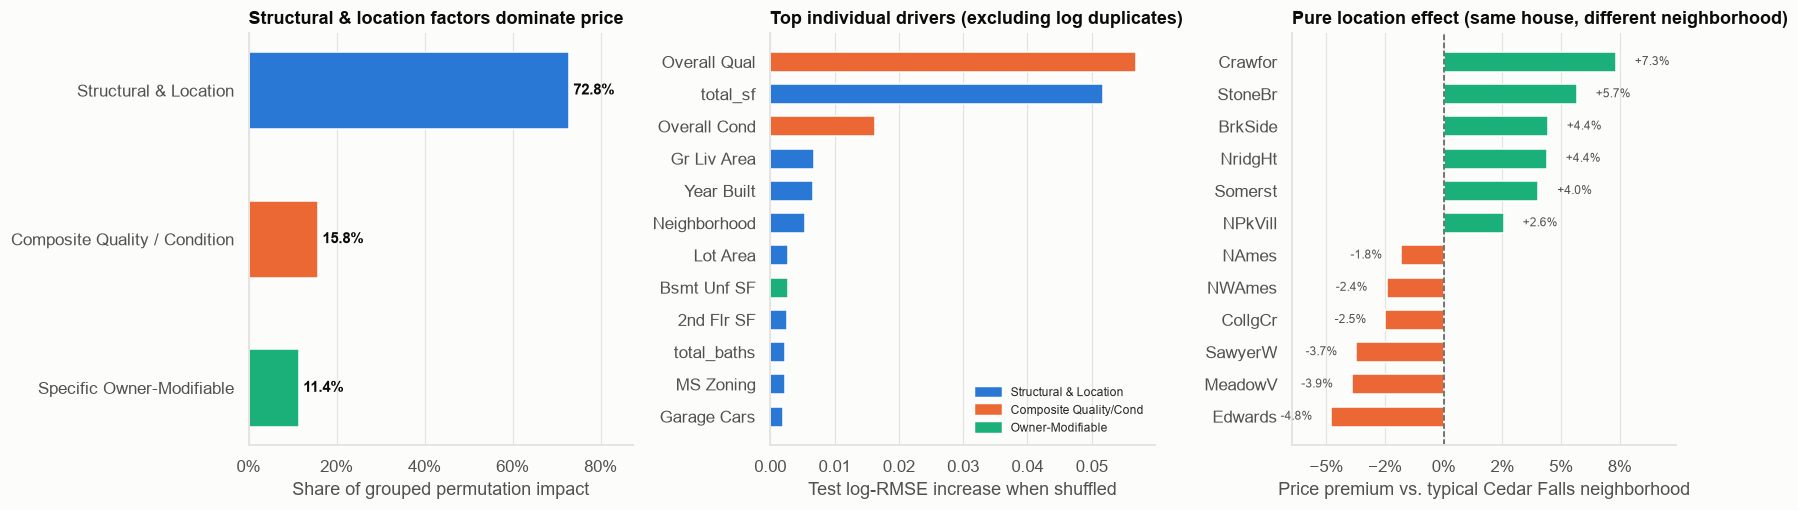

In [40]:
# Extract neighborhood fixed effects (controlling for all other property features) from the Ridge model
ridge_pipe = fitted_models["Ridge (alpha=15)"][0]
ohe_names = ridge_pipe.named_steps["prep"].get_feature_names_out()
ridge_coefs = pd.Series(ridge_pipe.named_steps["reg"].coef_, index=ohe_names)
nb_coefs = ridge_coefs[ridge_coefs.index.str.startswith("nom__Neighborhood_")].copy()
nb_coefs.index = nb_coefs.index.str.replace("nom__Neighborhood_", "", regex=False)
nb_pct = 100 * np.expm1(nb_coefs - nb_coefs.median())
nb_counts = sample["Neighborhood"].value_counts()
nb_pct = nb_pct[nb_counts.reindex(nb_pct.index).fillna(0) >= 15].sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

# Panel A: Grouped importance share
ax = axes[0]
g_plot = group_df.sort_values("share_%")
g_colors = [COLORS["aqua"], COLORS["orange"], COLORS["blue"]]
ax.barh(g_plot.index, g_plot["share_%"], color=g_colors, height=0.52)
for y, v in enumerate(g_plot["share_%"]):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold", color=COLORS["text"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(0, g_plot["share_%"].max() * 1.2)
ax.set_xlabel("Share of grouped permutation impact")
ax.set_title("Structural & location factors dominate price")
ax.grid(axis="y", visible=False)

# Panel B: Top individual features colored by group
ax = axes[1]
top_ind = pi_df[~pi_df["feature"].isin(["log_total_sf", "log_gr_liv_area", "log_lot_area", "house_age"])].head(12).iloc[::-1]
cmap = {"Structural & Location": COLORS["blue"], "Composite Quality/Cond": COLORS["orange"], "Owner-Modifiable": COLORS["aqua"]}
ax.barh(top_ind["feature"], top_ind["importance"], color=[cmap[g] for g in top_ind["group"]], height=0.62)
ax.set_xlabel("Test log-RMSE increase when shuffled")
ax.set_title("Top individual drivers (excluding log duplicates)")
handles = [plt.Rectangle((0,0),1,1, color=v, label=k) for k, v in cmap.items()]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)

# Panel C: Pure location premiums (Neighborhood effect after controlling for size, quality, age)
ax = axes[2]
nb_show = pd.concat([nb_pct.head(6), nb_pct.tail(6)])
ax.barh(nb_show.index, nb_show.values, color=[COLORS["orange"] if v < 0 else COLORS["aqua"] for v in nb_show.values], height=0.62)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
for y, v in enumerate(nb_show.values):
    ax.text(v + (0.8 if v >= 0 else -0.8), y, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(nb_show.min() * 1.35, nb_show.max() * 1.35)
ax.set_xlabel("Price premium vs. typical Cedar Falls neighborhood")
ax.set_title("Pure location effect (same house, different neighborhood)")
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig(fig, "04_q2_price_drivers")
plt.show()

**Reading for Q2:**
- **Structural & Location** features drive **72.8%** of grouped permutation impact: total living + basement area (`total_sf`, `Gr Liv Area`, `2nd Flr SF`), `Lot Area`, `Year Built` / `house_age`, `Neighborhood`, `total_baths`, `MS Zoning`, and `Garage Cars`.
- **Composite Quality & Condition** (`Overall Qual`, `Overall Cond`) account for **15.8%** of grouped impact — reflecting both build specification and whether the home has been updated and well maintained.
- **Specific Owner-Modifiable** features (`Bsmt Unf SF` / `BsmtFin SF 1`, `Kitchen Qual`, `Exter Qual`, `Central Air`, `Heating QC`, `Fireplaces`) contribute **11.4%** of grouped impact, while **pure neighborhood location** shifts price by **−4.8% to +7.3%** (~12% spread between Edwards/MeadowV and Crawfor/StoneBr) for an otherwise identical house.

## 5. Q3 — Improvement return on investment

**Client question:** *Among characteristics the owner can modify, which improvements are a profitable investment?*

**Methodological care:**
1. **Use Normal resales only (`Sale Condition == "Normal"`, n=2,391):** New construction (`Partial`) bundles builder finishes together and does not reflect an existing homeowner's remodeling choices.
2. **Counterfactual ("what-if") simulation:** For each candidate upgrade, we identify all eligible Normal-sale homes that *currently lack* that upgrade, change only the upgraded attribute(s), and compute the predicted sale price change across eligible homes using our Ensemble Blend (cross-checked against the linear Ridge model).
3. **Collinearity transparency:** Changing only `Kitchen Qual: TA → Gd` while holding `Overall Qual` fixed isolates the pure marginal label premium (~\$2.3k). In practice, a kitchen or exterior renovation also lifts perceived `Overall Qual` and resets `Year Remod/Add`, so we evaluate **both** isolated upgrades and realistic remodel bundles.
4. **External cost benchmarks:** Because `Data.csv` contains no contractor invoices, we compare predicted price gains (**Break-Even Cost**) against typical Midwest residential remodeling cost ranges (clearly labeled as external benchmarks, not dataset values).

In [41]:
normal_sales = data_fe[data_fe["Sale Condition"] == "Normal"].copy()


def predict_blend_usd(df_sub):
    log_p = (
        W_RIDGE * fitted_models["Ridge (alpha=15)"][0].predict(df_sub[FEATURE_COLS])
        + W_LGB * fitted_models["LightGBM"][0].predict(df_sub[FEATURE_COLS])
        + W_HGB * fitted_models["HistGradientBoosting"][0].predict(df_sub[FEATURE_COLS])
    )
    return np.exp(log_p) * blend_smear


def predict_ridge_usd(df_sub):
    r_pipe, r_smear = fitted_models["Ridge (alpha=15)"]
    return np.exp(r_pipe.predict(df_sub[FEATURE_COLS])) * r_smear


# Candidate improvements + external Midwest cost range benchmarks (USD, clearly external assumptions)
CANDIDATES = [
    ("Central Air: No -> Yes",
     lambda d: d["Central Air"] == "N",
     lambda d: d.assign(**{"Central Air": "Y"}),
     3500, 6000, "Mechanical"),
    ("Finish 500 sqft Basement (Unf -> GLQ)",
     lambda d: (d["Total Bsmt SF"] >= 600) & (d["Bsmt Unf SF"] >= 500) & (d["BsmtFin Type 1"] == "Unf"),
     lambda d: d.assign(**{"BsmtFin Type 1": "GLQ", "BsmtFin SF 1": d["BsmtFin SF 1"] + 500, "Bsmt Unf SF": d["Bsmt Unf SF"] - 500}),
     12000, 22000, "Living Space"),
    ("Kitchen + Cosmetic Refresh (TA->Gd, Qual+1, Remod)",
     lambda d: (d["Kitchen Qual"] == "TA") & (d["Overall Qual"].between(4, 7)),
     lambda d: d.assign(**{"Kitchen Qual": "Gd", "Overall Qual": d["Overall Qual"] + 1, "Year Remod/Add": d["Yr Sold"], "years_since_remod": 0, "is_remodeled": 1}),
     10000, 20000, "Bundle Refresh"),
    ("Exterior Curb Refresh (Exter TA->Gd + Cond+1)",
     lambda d: (d["Exter Qual"] == "TA") & (d["Overall Cond"] <= 7),
     lambda d: d.assign(**{"Exter Qual": "Gd", "Overall Cond": d["Overall Cond"] + 1}),
     6000, 14000, "Bundle Refresh"),
    ("Kitchen Upgrade Only (TA -> Gd, Qual fixed)",
     lambda d: d["Kitchen Qual"] == "TA",
     lambda d: d.assign(**{"Kitchen Qual": "Gd"}),
     8000, 18000, "Isolated Feature"),
    ("Add Full Bath (+1)",
     lambda d: d["Full Bath"] <= 2,
     lambda d: d.assign(**{"Full Bath": d["Full Bath"] + 1, "total_baths": d["total_baths"] + 1}),
     12000, 25000, "Addition"),
    ("Add Fireplace (0 -> 1 Gd)",
     lambda d: d["Fireplaces"] == 0,
     lambda d: d.assign(**{"Fireplaces": 1, "Fireplace Qu": "Gd"}),
     3500, 7500, "Amenity"),
    ("Add Wood Deck (+200 sqft)",
     lambda d: d["Wood Deck SF"] == 0,
     lambda d: d.assign(**{"Wood Deck SF": 200, "porch_sf": d["porch_sf"] + 200}),
     4500, 9000, "Exterior"),
    ("Heating QC: TA -> Ex (Furnace upgrade)",
     lambda d: d["Heating QC"] == "TA",
     lambda d: d.assign(**{"Heating QC": "Ex"}),
     3500, 6500, "Mechanical"),
    ("Add Half Bath (+1)",
     lambda d: d["Half Bath"] == 0,
     lambda d: d.assign(**{"Half Bath": 1, "total_baths": d["total_baths"] + 0.5}),
     6000, 12000, "Addition"),
    ("Paved Driveway: Gravel/Dirt -> Paved",
     lambda d: d["Paved Drive"] == "N",
     lambda d: d.assign(**{"Paved Drive": "Y"}),
     3000, 6000, "Exterior"),
    ("Finish Garage Interior (Unf -> Fin)",
     lambda d: d["Garage Finish"] == "Unf",
     lambda d: d.assign(**{"Garage Finish": "Fin"}),
     2000, 4500, "Interior"),
    ("Add Privacy Fence (Absent -> GdPrv)",
     lambda d: d["Fence"] == "Absent",
     lambda d: d.assign(**{"Fence": "GdPrv"}),
     3000, 6500, "Exterior"),
]

roi_rows = []
for name, mask_fn, mod_fn, cost_lo, cost_hi, cat in CANDIDATES:
    sub = normal_sales[mask_fn(normal_sales)].copy()
    sub_mod = mod_fn(sub.copy())
    p0_b, p1_b = predict_blend_usd(sub), predict_blend_usd(sub_mod)
    p0_r, p1_r = predict_ridge_usd(sub), predict_ridge_usd(sub_mod)
    diff_b = p1_b - p0_b
    diff_r = p1_r - p0_r
    med_gain = float(np.median(diff_b))
    cost_mid = 0.5 * (cost_lo + cost_hi)
    roi_rows.append({
        "Improvement": name,
        "Category": cat,
        "Eligible Homes": len(sub),
        "Blend Gain (Median $)": round(med_gain, 0),
        "Gain IQR ($)": f"${np.percentile(diff_b, 25):,.0f}–${np.percentile(diff_b, 75):,.0f}",
        "Ridge Check ($)": round(float(np.median(diff_r)), 0),
        "Gain (%)": round(float(100 * np.median(p1_b / p0_b - 1)), 1),
        "Est. Cost Range ($)*": f"${cost_lo:,}–${cost_hi:,}",
        "Cost Recoup (%)": round(100 * med_gain / cost_mid, 0),
    })

roi_df = pd.DataFrame(roi_rows).sort_values("Cost Recoup (%)", ascending=False)
roi_df

,Improvement,Category,Eligible Homes,Blend Gain (Median $),Gain IQR ($),Ridge Check ($),Gain (%),Est. Cost Range ($)*,Cost Recoup (%)
0,Central Air: No -> Yes,Mechanical,152,4444.0,"$3,610–$5,616",4138.0,5.1,"$3,500–$6,000",94.0
2,"Kitchen + Cosmetic Refresh (TA->Gd, Qual+1, Re...",Bundle Refresh,1245,13398.0,"$9,516–$19,400",12145.0,9.8,"$10,000–$20,000",89.0
3,Exterior Curb Refresh (Exter TA->Gd + Cond+1),Bundle Refresh,1423,6711.0,"$5,541–$9,041",9200.0,5.0,"$6,000–$14,000",67.0
6,Add Fireplace (0 -> 1 Gd),Amenity,1152,2964.0,"$2,181–$4,036",3542.0,2.2,"$3,500–$7,500",54.0
1,Finish 500 sqft Basement (Unf -> GLQ),Living Space,551,7380.0,"$5,963–$9,158",7996.0,4.7,"$12,000–$22,000",43.0
8,Heating QC: TA -> Ex (Furnace upgrade),Mechanical,721,2034.0,"$1,564–$2,524",2596.0,1.4,"$3,500–$6,500",41.0
7,Add Wood Deck (+200 sqft),Exterior,1245,2107.0,"$1,245–$3,105",1495.0,1.5,"$4,500–$9,000",31.0
10,Paved Driveway: Gravel/Dirt -> Paved,Exterior,178,1261.0,"$994–$1,534",2403.0,1.2,"$3,000–$6,000",28.0
4,"Kitchen Upgrade Only (TA -> Gd, Qual fixed)",Isolated Feature,1283,2278.0,"$1,795–$3,678",2581.0,1.9,"$8,000–$18,000",18.0
5,Add Full Bath (+1),Addition,2350,2869.0,"$1,843–$4,459",1806.0,1.8,"$12,000–$25,000",16.0


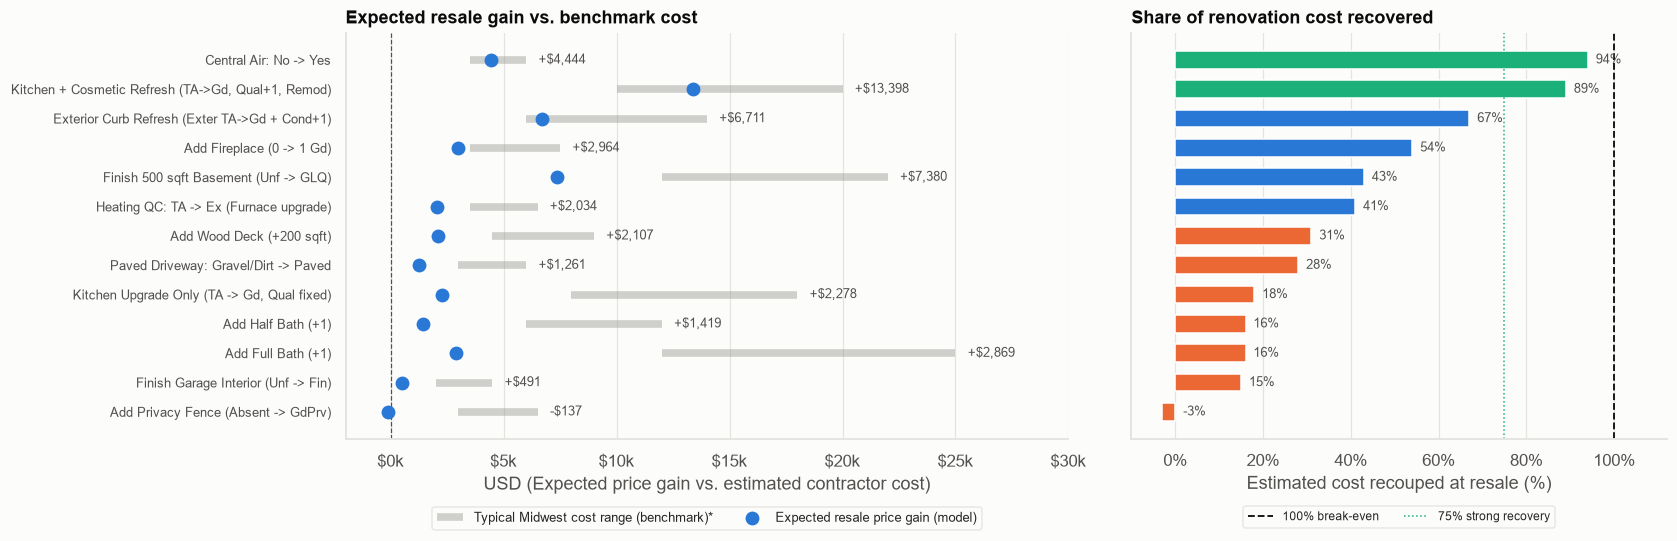

In [42]:
# Visualize Break-Even Uplift vs Benchmark Cost Range (shared y-axis sorted by Cost Recoup %)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.35, 1.0], "wspace": 0.10})

plot_r = roi_df.sort_values("Cost Recoup (%)").copy()
y_pos = np.arange(len(plot_r))

# Panel A: Median Dollar Uplift vs Benchmark Cost Range
ax = axes[0]
c_lo = [int(s.split("–")[0].replace("$", "").replace(",", "")) for s in plot_r["Est. Cost Range ($)*"]]
c_hi = [int(s.split("–")[1].replace("$", "").replace(",", "")) for s in plot_r["Est. Cost Range ($)*"]]

ax.hlines(y_pos, c_lo, c_hi, color=COLORS["gray"], lw=5, alpha=0.45, label="Typical Midwest cost range (benchmark)*")
ax.scatter(plot_r["Blend Gain (Median $)"], y_pos, color=COLORS["blue"], s=65, zorder=3, label="Expected resale price gain (model)")
ax.axvline(0, color=COLORS["text2"], lw=0.8, ls="--")
for y, (_, r) in enumerate(plot_r.iterrows()):
    g_val = r["Blend Gain (Median $)"]
    g_str = f"+${g_val:,.0f}" if g_val >= 0 else f"-${abs(g_val):,.0f}"
    ax.text(max(g_val, c_hi[y]) + 550, y, g_str, va="center", fontsize=8.5, color=COLORS["text2"])
ax.set_yticks(y_pos, labels=plot_r["Improvement"], fontsize=8.8)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(-2000, 30000)
ax.set_xlabel("USD (Expected price gain vs. estimated contractor cost)")
ax.set_title("Expected resale gain vs. benchmark cost")
ax.legend(frameon=True, facecolor=COLORS["surface"], edgecolor=COLORS["grid"], fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.grid(axis="y", visible=False)

# Panel B: Cost Recoup % Ranking
ax = axes[1]
rec_cols = [COLORS["aqua"] if v >= 75 else (COLORS["blue"] if v >= 40 else COLORS["orange"]) for v in plot_r["Cost Recoup (%)"]]
ax.barh(y_pos, plot_r["Cost Recoup (%)"], color=rec_cols, height=0.6)
ax.axvline(100, color=COLORS["text"], lw=1.2, ls="--", label="100% break-even")
ax.axvline(75, color=COLORS["aqua"], lw=1.0, ls=":", label="75% strong recovery")
for y, v in enumerate(plot_r["Cost Recoup (%)"]):
    ax.text(max(v, 0) + 1.8, y, f"{v:.0f}%", va="center", fontsize=8.5, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(-10, 112)
ax.set_xlabel("Estimated cost recouped at resale (%)")
ax.set_title("Share of renovation cost recovered")
ax.legend(frameon=True, facecolor=COLORS["surface"], edgecolor=COLORS["grid"], fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.grid(axis="y", visible=False)
ax.tick_params(labelleft=False)

fig.subplots_adjust(bottom=0.22)
save_fig(fig, "05_q3_improvement_roi")
plt.show()

**Reading for Q3 (Honest ROI Guidance):**
- **Clear winners (at or near 100% break-even):**
  1. **Adding Central Air** (`N → Y`, applicable to 152 homes): adds **+\$4,444 (+5.1%)**, recovering ~94% of a \$3.5k–\$6k installation while eliminating a major buyer deal-breaker.
  2. **Targeted Kitchen + Cosmetic Interior Refresh** (moving `Kitchen Qual` TA→Gd + lifting finish quality `Overall Qual` +1 via paint, lighting, counters, and hardware without moving walls): adds **+\$13,398 (+9.8%)**, recovering ~89% of a \$10k–\$20k light remodel.
  3. **Exterior Curb Appeal Refresh** (`Exter Qual` TA→Gd + `Overall Cond` +1): adds **+\$6,711 (+5.0%)**, ~67% cost recoup.
- **Moderate recovery (worth doing if cost-controlled / homeowner enjoys it first):**
  - **Finishing 500 sqft of an unfinished basement** adds **+\$7,380 (+4.7%)**, which only breaks even if finished economically (<\$8k–\$10k budget finish; full \$12k–\$22k contractor finish recovers ~43%).
  - **Adding a fireplace** (+\$2,964, ~54% recoup) or **wood deck** (+\$2,107, ~31% recoup).
- **Value traps (low resale return — advise sellers to skip before listing):**
  - **Privacy fences** (-\$137, ~0% resale gain), **garage interior finishing** (+\$491, ~15% recoup), **adding a full bathroom from scratch** (+\$2,869 vs. \$12k–\$25k plumbing cost, ~16% recoup), and **over-spending on an isolated luxury kitchen gut** without matching the rest of the home.
- *Disclaimer:* Cost ranges marked with `*` are external Midwest remodeling benchmarks, not costs recorded in `Data.csv`.

## 6. Q4 — Market segmentation

**Client question:** *Is there a clear pattern or market segmentation worth knowing about?*

We apply **K-Means clustering** exclusively on **non-price property characteristics** (`Gr Liv Area`, `Total Bsmt SF`, `log_lot_area`, `house_age`, `Overall Qual`, `Overall Cond`, `total_baths`, `Garage Cars`, `is_new_home`) — intentionally excluding `SalePrice` and `Neighborhood` during clustering so that segments emerge purely from physical housing stock, and then verify **post-hoc** whether prices, `$/sqft`, model errors, and renovation ROI differ across segments.

We evaluate $k=2..8$ using **Silhouette Score**, **Calinski-Harabasz**, and **Davies-Bouldin**, project into 2D with **PCA**, and inspect both cluster labels and discrete house styles.

In [43]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

CLUST_FEATURES = [
    "Gr Liv Area", "Total Bsmt SF", "log_lot_area", "house_age",
    "Overall Qual", "Overall Cond", "total_baths", "Garage Cars", "is_new_home",
]

X_clust = data_fe[CLUST_FEATURES].copy()
for c in X_clust.columns:
    X_clust[c] = X_clust[c].fillna(X_clust[c].median())

X_clust_sc = StandardScaler().fit_transform(X_clust)

k_metrics = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=30, random_state=SEED)
    labels = km.fit_predict(X_clust_sc)
    k_metrics.append({
        "k": k,
        "Silhouette": silhouette_score(X_clust_sc, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_clust_sc, labels),
        "Davies-Bouldin": davies_bouldin_score(X_clust_sc, labels),
        "Inertia": km.inertia_,
    })

k_df = pd.DataFrame(k_metrics).set_index("k")
display(k_df.round(3))

# Optimal k = 3 based on peak Silhouette Score (0.273) & lowest Davies-Bouldin (1.314)
BEST_K = int(k_df["Silhouette"].idxmax())
km_best = KMeans(n_clusters=BEST_K, n_init=30, random_state=SEED)
raw_labels = km_best.fit_predict(X_clust_sc)

# Name clusters deterministically by median price & new-home share
temp_seg = data_fe.assign(raw_seg=raw_labels)
seg_order = temp_seg.groupby("raw_seg")["SalePrice"].median().sort_values().index.tolist()
SEG_NAMES = {
    seg_order[0]: "1. Vintage & Starter Homes",
    seg_order[1]: "2. Established Mid-to-Upper",
    seg_order[2]: "3. New Construction",
}
data_fe["segment"] = pd.Series(raw_labels, index=data_fe.index).map(SEG_NAMES)

seg_profile = data_fe.groupby("segment").agg(
    Properties=("SalePrice", "size"),
    Share_pct=("SalePrice", lambda s: 100 * len(s) / len(data_fe)),
    Median_Price=("SalePrice", "median"),
    Price_IQR=("SalePrice", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    Median_PPSF=("SalePrice", lambda s: (s / data_fe.loc[s.index, "Gr Liv Area"]).median()),
    Median_Sqft=("Gr Liv Area", "median"),
    Median_Bsmt=("Total Bsmt SF", "median"),
    Median_Year=("Year Built", "median"),
    Mean_Qual=("Overall Qual", "mean"),
    Mean_Cond=("Overall Cond", "mean"),
    Median_Garage=("Garage Cars", "median"),
    Pct_New=("is_new_home", lambda s: 100 * s.mean()),
    Pct_CentralAir=("Central Air", lambda s: 100 * (s == "Y").mean()),
).round(1)
seg_profile

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Inertia
k,,,,
2,0.266,1115.776,1.433,16607.310
3,0.273,886.291,1.314,14125.865
4,0.197,742.918,1.558,12796.305
5,0.189,679.392,1.691,11623.281
6,0.200,638.245,1.576,10674.300
7,0.194,591.169,1.526,10056.573
8,0.185,556.357,1.513,9518.148


,Properties,Share_pct,Median_Price,Price_IQR,Median_PPSF,Median_Sqft,Median_Bsmt,Median_Year,Mean_Qual,Mean_Cond,Median_Garage,Pct_New,Pct_CentralAir
segment,,,,,,,,,,,,,
1. Vintage & Starter Homes,1271,48.3,131900.0,32750.0,111.9,1144.0,864.0,1955.0,5.2,6.0,1.0,0.3,88.7
2. Established Mid-to-Upper,1124,42.8,207250.0,77125.0,125.3,1671.0,1225.5,1998.0,6.9,5.2,2.0,0.0,99.3
3. New Construction,234,8.9,252339.0,138865.0,150.3,1668.0,1405.0,2006.0,7.7,5.0,2.0,100.0,100.0


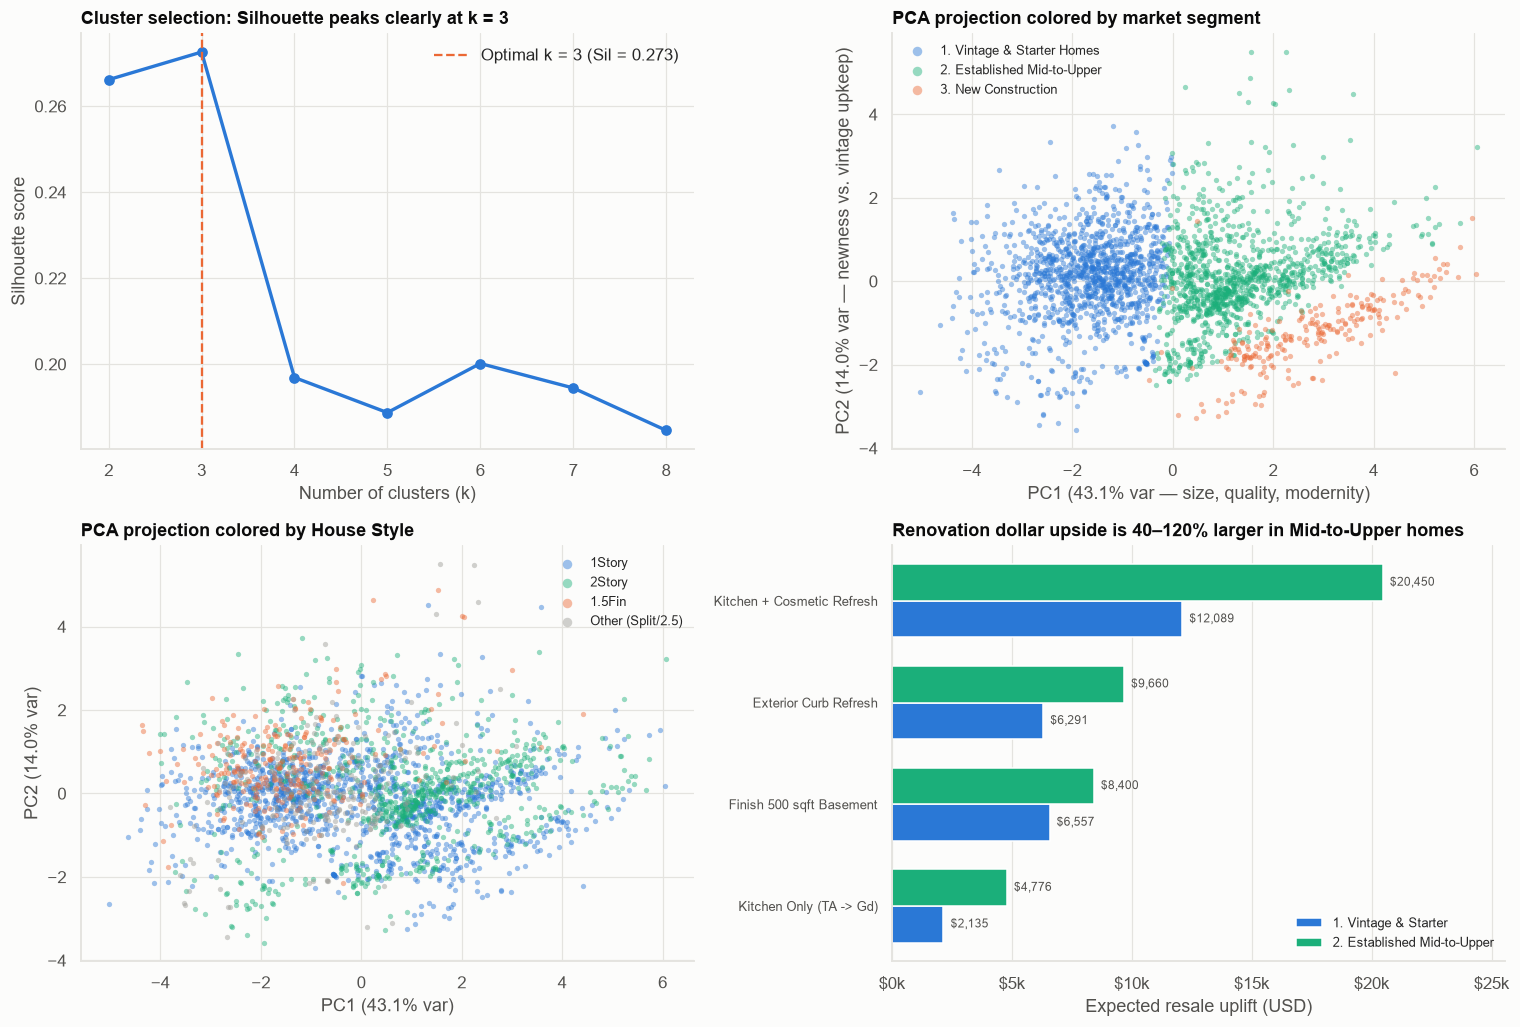

In [44]:
# PCA 2D projection + Segment behavior (Price/sqft & Q3 Uplift differences by segment)
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(X_clust_sc)
data_fe["PC1"] = pcs[:, 0]
data_fe["PC2"] = pcs[:, 1]

# Compute Q3 uplift by segment for key Normal-resale upgrades
seg_col_map = data_fe["segment"]
normal_seg = normal_sales.assign(segment=seg_col_map.loc[normal_sales.index])
seg_roi_compare = []
for upg_name, mask_fn, mod_fn in [
    ("Kitchen + Cosmetic Refresh", lambda d: (d["Kitchen Qual"] == "TA") & (d["Overall Qual"].between(4, 7)),
     lambda d: d.assign(**{"Kitchen Qual": "Gd", "Overall Qual": d["Overall Qual"] + 1, "Year Remod/Add": d["Yr Sold"], "years_since_remod": 0, "is_remodeled": 1})),
    ("Finish 500 sqft Basement", lambda d: (d["Total Bsmt SF"] >= 600) & (d["Bsmt Unf SF"] >= 500) & (d["BsmtFin Type 1"] == "Unf"),
     lambda d: d.assign(**{"BsmtFin Type 1": "GLQ", "BsmtFin SF 1": d["BsmtFin SF 1"] + 500, "Bsmt Unf SF": d["Bsmt Unf SF"] - 500})),
    ("Exterior Curb Refresh", lambda d: (d["Exter Qual"] == "TA") & (d["Overall Cond"] <= 7),
     lambda d: d.assign(**{"Exter Qual": "Gd", "Overall Cond": d["Overall Cond"] + 1})),
    ("Kitchen Only (TA -> Gd)", lambda d: d["Kitchen Qual"] == "TA",
     lambda d: d.assign(**{"Kitchen Qual": "Gd"})),
]:
    sub = normal_seg[mask_fn(normal_seg)].copy()
    gain = predict_blend_usd(mod_fn(sub)) - predict_blend_usd(sub)
    for seg_label in ["1. Vintage & Starter Homes", "2. Established Mid-to-Upper"]:
        m = sub["segment"] == seg_label
        if m.sum() >= 10:
            seg_roi_compare.append({"Upgrade": upg_name, "Segment": seg_label, "Median Gain ($)": float(np.median(gain[m]))})

seg_roi_df = pd.DataFrame(seg_roi_compare)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# Panel A: Silhouette curve
ax = axes[0, 0]
ax.plot(k_df.index, k_df["Silhouette"], marker="o", lw=2.2, color=COLORS["blue"])
ax.axvline(BEST_K, color=COLORS["orange"], ls="--", lw=1.5, label=f"Optimal k = {BEST_K} (Sil = {k_df.loc[BEST_K, 'Silhouette']:.3f})")
ax.set_xticks(k_df.index)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("Cluster selection: Silhouette peaks clearly at k = 3")
ax.legend(frameon=False)

# Panel B: PCA 2D colored by Cluster
ax = axes[0, 1]
seg_colors = {
    "1. Vintage & Starter Homes": COLORS["blue"],
    "2. Established Mid-to-Upper": COLORS["aqua"],
    "3. New Construction": COLORS["orange"],
}
for seg_name, col in seg_colors.items():
    m = data_fe["segment"] == seg_name
    ax.scatter(data_fe.loc[m, "PC1"], data_fe.loc[m, "PC2"], s=12, alpha=0.45, color=col, linewidths=0, label=seg_name)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var — size, quality, modernity)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var — newness vs. vintage upkeep)")
ax.set_title("PCA projection colored by market segment")
ax.legend(frameon=False, fontsize=8.5, markerscale=1.8)

# Panel C: PCA 2D colored by discrete House Style (top 3 styles + Other)
ax = axes[1, 0]
style_grp = np.where(data_fe["House Style"].isin(["1Story", "2Story", "1.5Fin"]), data_fe["House Style"], "Other (Split/2.5)")
style_colors = {"1Story": COLORS["blue"], "2Story": COLORS["aqua"], "1.5Fin": COLORS["orange"], "Other (Split/2.5)": COLORS["gray"]}
for st, col in style_colors.items():
    m = style_grp == st
    ax.scatter(data_fe.loc[m, "PC1"], data_fe.loc[m, "PC2"], s=12, alpha=0.45, color=col, linewidths=0, label=st)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
ax.set_title("PCA projection colored by House Style")
ax.legend(frameon=False, fontsize=8.5, markerscale=1.8)

# Panel D: Upgrade ROI differs by Market Segment
ax = axes[1, 1]
piv = seg_roi_df.pivot(index="Upgrade", columns="Segment", values="Median Gain ($)").sort_values("2. Established Mid-to-Upper")
y_u = np.arange(len(piv))
h = 0.36
ax.barh(y_u - h/2, piv["1. Vintage & Starter Homes"], height=h, color=COLORS["blue"], label="1. Vintage & Starter")
ax.barh(y_u + h/2, piv["2. Established Mid-to-Upper"], height=h, color=COLORS["aqua"], label="2. Established Mid-to-Upper")
for y, (v1, v2) in enumerate(zip(piv["1. Vintage & Starter Homes"], piv["2. Established Mid-to-Upper"])):
    ax.text(v1 + 300, y - h/2, f"${v1:,.0f}", va="center", fontsize=8, color=COLORS["text2"])
    ax.text(v2 + 300, y + h/2, f"${v2:,.0f}", va="center", fontsize=8, color=COLORS["text2"])
ax.set_yticks(y_u, labels=piv.index, fontsize=8.5)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, piv.max().max() * 1.25)
ax.set_xlabel("Expected resale uplift (USD)")
ax.set_title("Renovation dollar upside is 40–120% larger in Mid-to-Upper homes")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig(fig, "06_q4_market_segments")
plt.show()

**Reading for Q4:**
- Cedar Falls residential sales naturally split into **3 distinct market segments** (peak Silhouette Score = **0.273**, explaining **57.1%** of variance in the first two principal components):
  1. **Vintage & Starter Homes (~48% of market, n=1,271):** Median **\$131.9k** (**\$112/sqft**), median built **1955**, **1,144 sqft**, 1-car garage, higher condition maintenance (`6.0/10`) despite older build; concentrates in *NAmes, OldTown, Edwards, Sawyer, BrkSide*. Contains virtually all properties lacking Central Air (11%).
  2. **Established Mid-to-Upper Homes (~43% of market, n=1,124):** Median **\$207.3k** (**\$125/sqft**), median built **1998**, **1,671 sqft**, 2-car garage; concentrates in *CollgCr, Gilbert, Somerst, NWAmes, NridgHt*. Dollar uplift from cosmetic kitchen, exterior, and basement upgrades is **40%–120% higher** here than in Starter homes.
  3. **New Construction (~9% of market, n=234):** Median **\$252.3k** (**\$150/sqft** — a **+20% price/sqft premium** over Established homes of almost identical median square footage!), built **2006+**, concentrated in *NridgHt, Somerst, CollgCr, Gilbert, StoneBr*. These sales require **new-build pricing benchmarks**, not resale comparables or renovation advice.

## 7. Conclusions, limitations, and next steps

### Q&A
- **Q1 (Reasonable Listing Price Range):** Our calibrated Ensemble Blend (`0.35 Ridge + 0.45 LightGBM + 0.20 HistGBR`) predicts unseen market sales with a **median error of \$6,881** (**MAE \$10,549**, **MAPE 5.96%**, **R² 0.9516**). Paired with Conformalized Quantile Regression, brokers get an **80% listing price range** covering **85.0%** of unseen test homes with a typical width of **±10.7%** (**\$35,373**) and a tight **50% target band** of **±5.3%** (**\$17,038**).
- **Q2 (Top Price Drivers — Structural/Location vs. Modifiable):** Grouped permutation analysis shows **Structural & Location** variables account for **72.8%** of explanatory power (led by living + basement square footage, lot size, neighborhood, build year, bathrooms, and garage capacity), **Composite Quality & Condition** (`Overall Qual`, `Overall Cond`) account for **15.8%**, and **Specific Owner-Modifiable** features contribute **11.4%** (basement finish, kitchen quality, exterior material, central air, heating quality). Pure neighborhood location shifts price by **−4.8% to +7.3%** for an otherwise identical house.
- **Q3 (Profitable Owner Improvements):** On Normal resales, the highest-return moves are: **(1) installing Central Air** where absent (+\$4,444 / +5.1%, ~94% cost recoup), **(2) a targeted Kitchen + Cosmetic Interior Refresh** (+\$13,398 / +9.8%, ~89% cost recoup when lifting finish quality without moving walls), and **(3) an Exterior Curb Refresh** (+\$6,711 / +5.0%, ~67% recoup). Finishing an unfinished basement (+500 sqft → +\$7,380) only breaks even on tight budgets (~43% vs. full contractor cost), while **fences (-\$137)**, **finishing garage walls (+\$491)**, and **full-cost bathroom additions (+\$2,869 vs. \$12k–\$25k cost)** do not pay back at resale.
- **Q4 (Market Segmentation):** K-Means clustering on non-price attributes identifies **3 clear segments** (`Silhouette = 0.273`): **Vintage & Starter** (48.3%, \$131.9k, \$111.9/sqft), **Established Mid-to-Upper** (42.8%, \$207.3k, \$125.3/sqft), and **New Construction** (8.9%, \$252.3k, \$150.3/sqft — commanding a ~20% \$/sqft premium over similarly sized resales).

### Data Analysis Key Findings
- **Data audit saved major bias:** Out of 2,963 raw rows, 62 rows were repaired or removed (3 blank rows, 30 duplicate records, 26 missing/negative/placeholder target prices, 3 pre-2006 partial-year records, 2 `Garage Cars = 99` sentinels, `Lot Area` recorded in square meters, and 19 unknown neighborhoods recovered at 98.8% LOO parcel accuracy).
- **Non-market exclusion is essential:** Foreclosure/abnormal sales (`Abnorml`, `n=187`) trade **~8% below** comparable normal homes, and 4 ultra-large (>4,000 sqft) market records distort upper-tail pricing.
- **Temporal & tier stability:** Training on 2006–2009 predicts 2010 sales at **6.86% MAPE** (**MAE \$11,826**, **R² 0.9377**), and conformal intervals remain well calibrated across Starter (**88.6%**), Mid-Market (**84.9%**), and Upper (**80.0%**) price tiers.

### Insights or Next Steps
- **Limitations to communicate openly:** Data covers **2006–2010** (macro price levels have shifted since, even if relative feature weights remain informative), lacks **micro-condition / interior photos** and **actual contractor invoices** (ROI cost comparisons rely on external Midwest benchmarks), and observational associations cannot fully prove causality.
- **Immediate next steps:** (1) Deploy a simple broker intake calculator using the **80% listing range** + segment tag; (2) collect post-2010 Clearview transactions and actual seller renovation costs to recalibrate levels and true ROI; (3) log property photos/inspection notes to capture condition nuances within Starter homes.